# Biogeochemical (BGC) model–data comparison at the HV stations

This notebook compares observed and modeled alkalinity, DIC, nutrients, chlorophyll and dissolved oxygen at the HV sampling stations in Hvalfjörður. Observations are the quality-controlled discrete samples from SEANOE dataset 110401 (`discrete_samples_qc.xlsx`); model fields are the BGC (`output_bgc`) and physical (`output_rst`) output of the C-Star run `iceland2_customriver`, regridded to depths of 0–30 m and sampled at the grid point and output time nearest to each station visit. The figures show a station map, boxplots by cruise, along-fjord sections, mean depth profiles and layer-averaged time series, a map of surface alkalinity and DIC around Iceland from the `UNIFIED/BGCdataset.nc` product, and a November 2024 comparison of a moored pCO$_2$ sensor with surface pCO$_2$ from a different run, `Iceland2_MARBL_2024_60m`.

## Data processing

The cells in this section load the observations and model output, apply quality control and unit conversions, compute salinity-normalized alkalinity and DIC, and extract model values at the station positions and observation dates.

### Imports

Libraries used throughout the notebook, including `gsw` for seawater density and the local module `roms_regrid` (`roms_regrid.py` in this directory), which regrids ROMS grid fields bilinearly to a regular latitude–longitude grid.

In [1]:
import subprocess
import os
import pandas as pd
#import netCDF4
import numpy as np
import glob
import time
import matplotlib.pyplot as plt
import copy
import xarray as xr
from datetime import datetime, timedelta 
import dask
from scipy.interpolate import griddata
#from ocean_c_lab_tools import *
#from celluloid import Camera 
#import PyCO2SYS as csys
import gsw as sw
from roms_regrid import *

### Input paths

Paths to the model grid, the discrete-sample spreadsheet, and the output files of the run `iceland2_customriver` (`bgc_model_paths` for BGC tracers, `phys_model_paths` for physical fields). `phys_model_paths1` points to history files of the run `Iceland2_MARBL_2024_60m` and is not used in this notebook.

In [2]:
model_grid_path="/anvil/scratch/x-uheede/cstar/iceland2_customriver/tasks/segment1/input/input_datasets/Iceland2_NEW_customriver_Iceland2_NEW_256procs_grid.nc"
obs_bgc_path='/anvil/projects/x-ees250129/x-uheede/C-Star-in-Hvalfjordur/data/staged/seanoe_hvalfjordur/2026-04-27/seanoe_110401/discrete_samples_qc/discrete_samples_qc.xlsx'

bgc_model_paths = [
    "/anvil/scratch/x-uheede/cstar/iceland2_customriver/gathered_output/output_bgc.2024??????????.nc"
]

phys_model_paths1 = [
    "/anvil/projects/x-ees250129/x-uheede/Iceland_experiments/Iceland2_MARBL_2024_60m/Iceland2_MARBL_2024_his.2024??????????.nc"
]

phys_model_paths = [
    "/anvil/scratch/x-uheede/cstar/iceland2_customriver/gathered_output/output_rst.2024??????????.nc"
]


### Observations: discrete samples

The spreadsheet is read, station names (e.g. `HV1`) are converted to station numbers, and sample depths are grouped into 10 m bins. Sampling years recorded as 2025 are set to 2024 before the time coordinate is built, and the table is reshaped into an xarray Dataset with dimensions `HV`, `depth_bin` and `time`.

In [3]:
import pandas as pd
import numpy as np
import xarray as xr

xls = pd.ExcelFile(obs_bgc_path)
combo = pd.read_excel(xls, 'Sheet1', decimal='.', header=27, skiprows=[28])

# We use .str.replace with regex=False for a simple string swap
combo['HV'] = combo['Station_name'].str.replace('HV', '', regex=False).astype(int)

# --- NEW: Convert all 2025 year values to 2024 ---
combo.loc[combo['Year_UTC'] == 2025, 'Year_UTC'] = 2024

# 2. Create the 'time' column (now properly using 2024 instead of 2025)
combo['time'] = pd.to_datetime(combo[['Year_UTC', 'Month_UTC', 'Day_UTC']].rename(
    columns={'Year_UTC': 'year', 'Month_UTC': 'month', 'Day_UTC': 'day'}
))

# -----------------------------
# CREATE DEPTH BINS (0–9.9, 10–19.9, ...)
# -----------------------------
combo["depth_bin"] = (np.floor(combo["Depth"] / 10) * 10).astype(int)

obs = xr.Dataset.from_dataframe(combo)
obs = obs.set_index(index=['HV', 'depth_bin', 'time'])
obs = obs.drop_duplicates('index')  # This will handle any duplicate index conflicts caused by the year shift
obs = obs.unstack('index')
obs = obs.rename(name_dict={'Latitude': 'lat', 'Longitude': 'lon'})

### Observations: unit conversion, QC and salinity normalization

Alkalinity and DIC are converted from per-mass to per-volume units (mmol m$^{-3}$) using potential density from `gsw` (sigma0). Only samples with QC flag 2 for temperature, salinity, TA and DIC are kept, and salinity-normalized values are computed as $nX = (X - X_0)/S \cdot S_{ref} + X_0$ with $S_{ref}$ = 34, $X_0$ = 282 for alkalinity (`nTA`) and $X_0$ = 313 for DIC (`nDIC`).

In [5]:
density=sw.density.sigma0(obs['Salinity_CTD'],obs['Temperature_CTD'])

obs['Alk']=obs['TA'] * (1 / 1000) * (density+1000)
obs['DIC']=obs['DIC'] * (1 / 1000) * (density+1000)

In [6]:
# -----------------------------
# QC MASK (all variables must pass)
# -----------------------------
qc_mask = (
    (obs["TEMP_flag"] == 2) &
    (obs["Salinity_CTD_flag"] == 2) &
    (obs["TA_flag"] == 2) &
    (obs["DIC_flag"] == 2)
)

# -----------------------------
# APPLY MASK INTO obs (IMPORTANT)
# -----------------------------
obs["Alk_qc"]      = obs["Alk"].where(qc_mask)
obs["DIC_qc"]      = obs["DIC"].where(qc_mask)
obs["Salinity_qc"] = obs["Salinity_CTD"].where(qc_mask)

# -----------------------------
# Constants
# -----------------------------
TA0 = 282
Sref = 34
DIC0 = 313

# -----------------------------
# NORMALIZATION (QC-CONSISTENT)
# -----------------------------
obs["nTA"] = ((obs["Alk_qc"] - TA0) / obs["Salinity_qc"]) * Sref + TA0
obs["nDIC"] = ((obs["DIC_qc"] - DIC0) / obs["Salinity_qc"]) * Sref + DIC0

### Model grid

A `roms_tools` `Grid` object is created from the model grid file.

In [7]:
from roms_tools import Grid, ROMSOutput

In [8]:
grid = Grid.from_file(model_grid_path)

### Model output and bathymetry

`ROMSOutput` objects are opened (with dask) for the BGC and physical output files. The grid file is then reopened with xarray, replacing the `Grid` object in `grid`, and bathymetry (`h`) and the land mask (`mask_rho`) are regridded with `roms_regrid` for the station map.

In [9]:
roms_output_bgc = ROMSOutput(
    grid=grid,
    path=bgc_model_paths,
    use_dask=True,
)

roms_output_phys = ROMSOutput(
    grid=grid,
    path=phys_model_paths,
    use_dask=True,
)

In [10]:
# open grid
grid=xr.open_mfdataset(model_grid_path)

# regridding
h=roms_regrid(grid,grid['h'])

mask=roms_regrid(grid,grid['mask_rho'])

### Regridding to fixed depth levels

The BGC tracers in `var_names` and the physical fields are regridded to depths of 0, 10, 20 and 30 m. Constant offsets are then added to the modeled carbon fields (+60 to `ALK`, +80 to `DIC`); all model alkalinity and DIC values below include these offsets.

In [11]:
var_names=['ALK','DIC','PO4','NO3','SiO3','NH4','O2','Fe',"spChl","diatChl"]
depth_levels=np.arange(0, 40,10)

In [12]:
bgc = roms_output_bgc.regrid(depth_levels=depth_levels,var_names=var_names).load()
phys = roms_output_phys.regrid(depth_levels=depth_levels)

In [13]:
bgc['ALK']=bgc['ALK']+60
bgc['DIC']=bgc['DIC']+80

### Duplicate model time stamps

Duplicate time stamps are removed from the regridded BGC and physical datasets, which are then sorted by time.

In [14]:
time_index = bgc.indexes['time']
unique_time = ~time_index.duplicated()

bgc = bgc.isel(time=unique_time)
bgc = bgc.sortby('time')

In [15]:
time_index = phys.indexes['time']
unique_time = ~time_index.duplicated()

phys = phys.isel(time=unique_time)
phys = phys.sortby('time')

### Model salinity normalization

Modeled `nTA` and `nDIC` are computed with the same formula and constants as the observations, using model salinity (`salt`) from the physical output.

In [16]:
Sref=34
#nTA_model=((bgc['ALK'].load()-TA0)/phys['salt'].thin({'time': 24}).load())*Sref+TA0

#nDIC_model=((bgc['DIC'].load()-DIC0)/phys['salt'].thin({'time': 24}).load())*Sref+DIC0

nTA_model=((bgc['ALK'].load()-TA0)/phys['salt'].load())*Sref+TA0

nDIC_model=((bgc['DIC'].load()-DIC0)/phys['salt'].load())*Sref+DIC0
bgc['nTA']=nTA_model
bgc['nDIC']=nDIC_model

### Station positions and model profiles

The position of each station is the time-mean latitude and longitude of its shallowest depth bin in the observations. The regridded BGC fields are sampled at the model grid point nearest to the first seven stations, which are labelled 1, 3, 5, 7, 9, 10 and 12, and the sign of the model depth coordinate is reversed.

In [17]:
# define location which calculations the average location of each station
def get_location(obs, hv_values):
    locations = []
    for hv in hv_values:
        lat = obs['lat'].sel(HV=hv).isel(depth_bin=0).mean('time').squeeze().values
        lon = obs['lon'].sel(HV=hv).isel(depth_bin=0).mean('time').squeeze().values + 360
        locations.append([lat, lon])
    return locations

# List of HV values
hv_values = np.unique(obs['HV'].values)

# Get the locations
locations = get_location(obs, hv_values)

In [18]:
# Assuming locations is a list of lat/lon pairs
bgc_values = []

# Loop over the first 10 locations and store each selection in t_values
for i in range(7):
    lat, lon = locations[i]
    
    # Select the 't' values at the nearest lat/lon
    bgc_selected = bgc.sel(lat=lat, method='nearest').sel(lon=lon, method='nearest')
    
    # Store the result in the list
    bgc_values.append(bgc_selected)

# Combine the selections into an xarray Dataset or DataArray
bgc_values_combined = xr.concat(bgc_values, dim='location')

# Assign a location coordinate for clarity (optional)
bgc_values_combined = bgc_values_combined.assign_coords(location=('location', [1,3,5,7,9,10,12]))
bgc_values_combined['depth']=bgc_values_combined.depth*(-1)


### Model output at the observation dates

For each unique observation date, the nearest model output time is selected and relabelled with the observation date (`bgc_sub`). The same station and date extraction is applied to the physical fields (`phys_sub`), which provide model temperature for the oxygen saturation calculation further down.

In [19]:
import pandas as pd
import numpy as np

# 1. Extract unique time list from obs (the actual cruise dates)
time_list = np.unique(obs['time'].values)

# 2. Select nearest model output using the original observation dates
bgc_sub = bgc_values_combined.sel(
    time=time_list,
    method='nearest'
)

# 3. OVERWRITE the coordinate labels if you need them to perfectly mirror 
# the precise 'obs' timeline in later analysis steps
bgc_sub = bgc_sub.assign_coords(time=time_list)

In [46]:
import numpy as np
import pandas as pd
import xarray as xr

# ====================================================
# Extract Physical Model Output (phys_sub)
# ====================================================

# Assuming locations is a list of lat/lon pairs
phys_values = []

# Loop over the first 7 locations and store each selection
for i in range(7):
    lat, lon = locations[i]

    # Select the physics values at the nearest lat/lon
    phys_selected = phys.sel(lat=lat, method="nearest").sel(
        lon=lon, method="nearest"
    )

    # Store the result in the list
    phys_values.append(phys_selected)

# Combine the selections into an xarray Dataset or DataArray
phys_values_combined = xr.concat(phys_values, dim="location")

# Assign the matching location coordinate labels
phys_values_combined = phys_values_combined.assign_coords(
    location=("location", [1, 3, 5, 7, 9, 10, 12])
)

# Invert depth coordinate to positive downwards if needed
if "depth" in phys_values_combined.coords or "depth" in phys_values_combined:
    phys_values_combined["depth"] = phys_values_combined.depth * (-1)

# 1. Extract unique time list from obs (the actual cruise dates)
time_list = np.unique(obs["time"].values)

# 2. Select nearest model output using the original observation dates
phys_sub = phys_values_combined.sel(time=time_list, method="nearest")

# 3. Overwrite the coordinate labels to mirror the obs timeline
phys_sub = phys_sub.assign_coords(time=time_list)

In [47]:
phys_sub.load()

<xarray.Dataset> Size: 222kB
Dimensions:                (location: 7, time: 22, depth: 4)
Coordinates:
    lat                    (location) float32 28B 64.26 64.29 ... 64.36 64.36
    lon                    (location) float32 28B 338.0 338.2 ... 338.3 338.3
  * depth                  (depth) float32 16B -0.0 -10.0 -20.0 -30.0
  * location               (location) int64 56B 1 3 5 7 9 10 12
  * time                   (time) datetime64[ns] 176B 2024-01-09 ... 2024-11-21
Data variables: (12/60)
    zeta                   (location, time) float64 1kB -1.363 ... -0.1705
    MARBL_PH_3D            (location, time, depth) float64 5kB 8.135 ... 8.133
    MARBL_PH_3D_ALT_CO2    (location, time, depth) float64 5kB 8.135 ... 8.133
    MARBL_PH_SURF          (location, time) float64 1kB 8.142 8.135 ... 8.135
    MARBL_ABIO_PH_SURF     (location, time) float64 1kB 0.0 0.0 0.0 ... 0.0 0.0
    MARBL_PH_SURF_ALT_CO2  (location, time) float64 1kB 8.142 8.135 ... 8.135
    ...                     ...
    DV_avg1                (location, time) float64 1kB 228.3 175.5 ... -351.3
    DV_avg2                (location, time) float64 1kB 227.8 177.0 ... -351.2
    DV_avg_bak             (location, time) float64 1kB 204.1 160.1 ... -315.1
    v_slow                 (location, time, depth) float64 5kB 0.05865 ... 0....
    riv_vmask              (location, time) float64 1kB 0.0 0.0 0.0 ... 0.0 0.0
    mask_v                 (location) float64 56B 1.0 1.0 1.0 1.0 1.0 1.0 1.0
Attributes: (12/47)
    partition:          [  0 256   1   1]
    globaldims:         [514 514]
    global_x:           512
    global_y:           512
    title:              Iceland2_NEW_customriver_Iceland2_NEW_256procs_202302...
    grid_file:          N/A
    ...                 ...
    river_frc_options:  OFF
    pipe_frc_options:   OFF
    particle_options:   OFF
    git_version:        
    type:               ROMS restart file
    regrid_method:      bilinear

The processed subset is loaded into memory as the final input for the plotting section.

In [20]:
bgc_sub.load()

<xarray.Dataset> Size: 59kB
Dimensions:   (location: 7, time: 22, depth: 4)
Coordinates:
    lat       (location) float32 28B 64.26 64.29 64.3 64.31 64.34 64.36 64.36
    lon       (location) float32 28B 338.0 338.2 338.1 338.1 338.2 338.3 338.3
  * depth     (depth) float32 16B -0.0 -10.0 -20.0 -30.0
  * location  (location) int64 56B 1 3 5 7 9 10 12
  * time      (time) datetime64[ns] 176B 2024-01-09 2024-02-17 ... 2024-11-21
Data variables:
    ALK       (location, time, depth) float64 5kB 2.352e+03 ... 2.315e+03
    DIC       (location, time, depth) float64 5kB 2.201e+03 ... 2.158e+03
    PO4       (location, time, depth) float64 5kB 0.5326 0.5328 ... 0.3787
    NO3       (location, time, depth) float64 5kB 6.869 6.873 ... 4.39 4.442
    SiO3      (location, time, depth) float64 5kB 4.209 4.209 ... 3.704 3.711
    NH4       (location, time, depth) float64 5kB 0.04718 0.04687 ... 0.3303
    O2        (location, time, depth) float64 5kB 328.2 323.5 ... 314.3 313.2
    Fe        (location, time, depth) float64 5kB 0.003 0.003 ... 0.003 0.003
    spChl     (location, time, depth) float64 5kB 0.004479 0.004483 ... 0.006703
    diatChl   (location, time, depth) float64 5kB 0.01688 0.01689 ... 0.03221
    nTA       (location, time, depth) float64 5kB 2.317e+03 ... 2.313e+03
    nDIC      (location, time, depth) float64 5kB 2.169e+03 ... 2.157e+03
Attributes: (12/46)
    partition:          [  0 256   1   1]
    globaldims:         [514 514]
    global_x:           512
    global_y:           512
    title:              Iceland2_NEW_customriver_Iceland2_NEW_256procs_202302...
    grid_file:          N/A
    ...                 ...
    tide_options:       # of constituents:15 , real , tidalpotential
    river_frc_options:  OFF
    pipe_frc_options:   OFF
    particle_options:   OFF
    git_version:        
    regrid_method:      bilinear

## Station map and salinity-normalized alkalinity by cruise

The top panel shows model bathymetry with the station numbers. The lower panels show boxplots of salinity-normalized alkalinity for each of the first 22 observation dates, observed (left) and modeled (right), for all depths (middle row) and for the surface level only (bottom row).

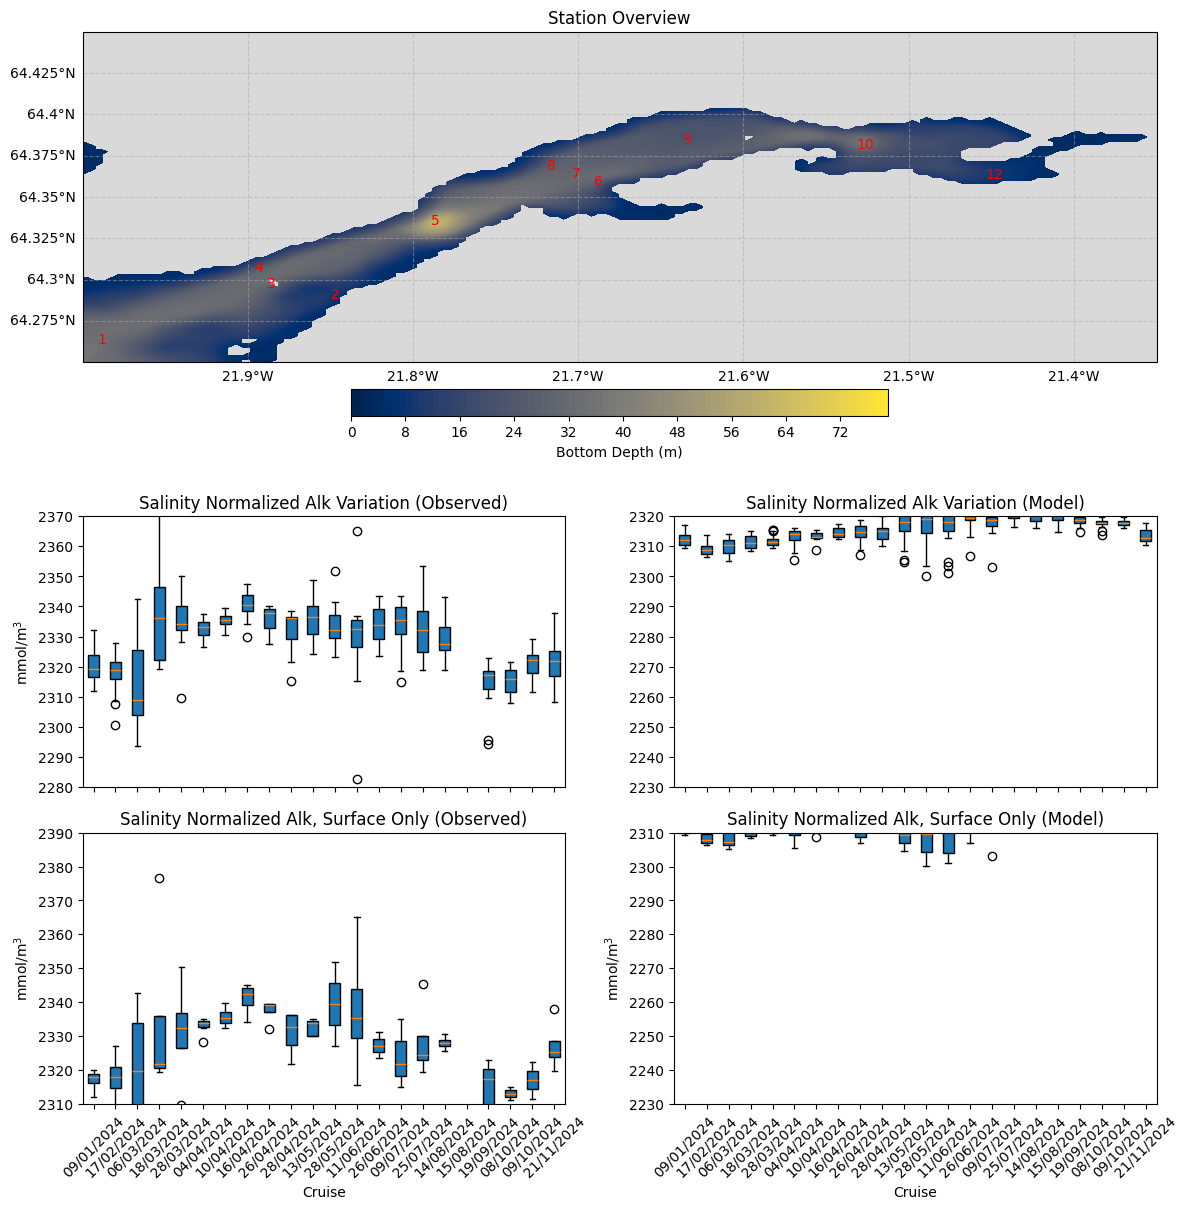

In [21]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Define depth levels
levels = np.arange(0, 80)

# Create figure and subplots (3 rows: 1 for the map, 2 for boxplots)
fig = plt.figure(figsize=(12, 13))  # Wider figure for side-by-side plots
gs = fig.add_gridspec(3, 2, height_ratios=[2, 1, 1], width_ratios=[1, 1])  

# --- Shared Map (Top Row, Spanning Both Columns) ---
ax_map = fig.add_subplot(gs[0, :], projection=ccrs.PlateCarree())

# Plot bathymetry
cf1 = ax_map.contourf(h.lon, h.lat, h, levels, transform=ccrs.PlateCarree(), cmap='cividis')
ax_map.contourf(h.lon, h.lat, mask.where(mask != 1), cmap='Greys', transform=ccrs.PlateCarree())

# Add station labels
for i, e in enumerate(locations):
    ax_map.text(e[1], e[0], hv_values[i], color='red', size=10, ha='center', va='center', transform=ccrs.PlateCarree())

# Gridlines
gls = ax_map.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, color='darkgray', alpha=0.5, linestyle='--')
gls.top_labels = False
gls.right_labels = False

# Colorbar
cb1 = plt.colorbar(cf1, shrink=0.5, ax=ax_map, orientation='horizontal', pad=0.05)
cb1.set_label('Bottom Depth (m)', fontsize=10)

ax_map.set_extent([-22, -21.35, 64.25, 64.45], ccrs.PlateCarree())
ax_map.set_title('Station Overview')

# --- Function for Extracting Data ---
def extract_cruise_data(var, depth=None, num_cruises=22):
    """Extracts non-NaN values for a given variable across cruises."""
    cruises = []
    for i in range(num_cruises):
        data = np.hstack(var.isel(time=i) if depth is None else var.isel(time=i, depth_bin=depth))
        cruises.append(data[~np.isnan(data)])
    return cruises

def extract_model_data(var, depth=None, num_cruises=22):
    """Extracts non-NaN values from the model across time steps."""
    cruises = []
    for i in range(num_cruises):
        data = np.hstack(var.isel(time=i) if depth is None else var.isel(time=i, depth=depth))
        cruises.append(data[~np.isnan(data)])
    return cruises

# --- Boxplots for Observations (Left) and Model (Right) ---
ax_obs = fig.add_subplot(gs[1, 0])  # Observations
ax_model = fig.add_subplot(gs[1, 1])  # Model

ax_obs.boxplot(extract_cruise_data(obs["nTA"]), patch_artist=True)
ax_obs.set_title('Salinity Normalized Alk Variation (Observed)')
ax_obs.set_ylabel('mmol/m$^3$')
ax_obs.set_xticklabels([])
ax_obs.set_ylim(2280,2370)

ax_model.boxplot(extract_model_data(bgc_sub['nTA']), patch_artist=True)
ax_model.set_title('Salinity Normalized Alk Variation (Model)')
ax_model.set_xticklabels([])
ax_model.set_ylim(2230,2320)

# --- Surface-Only Boxplots for Observations (Left) and Model (Right)---
ax_obs_surface = fig.add_subplot(gs[2, 0])  # Observations (Surface)
ax_model_surface = fig.add_subplot(gs[2, 1])  # Model (Surface)

ax_obs_surface.boxplot(extract_cruise_data(obs["nTA"], depth=0), patch_artist=True)
ax_obs_surface.set_title('Salinity Normalized Alk, Surface Only (Observed)')
ax_obs_surface.set_xlabel('Cruise')
ax_obs_surface.set_ylabel('mmol/m$^3$')
ax_obs_surface.set_xticklabels(pd.to_datetime(obs['time'].isel(time=slice(0,22))).strftime('%d/%m/%Y'), rotation=45)
ax_obs_surface.set_ylim(2310,2390)

ax_model_surface.boxplot(extract_model_data(bgc_sub['nTA'], depth=0), patch_artist=True)
ax_model_surface.set_title('Salinity Normalized Alk, Surface Only (Model)')
ax_model_surface.set_xlabel('Cruise')
ax_model_surface.set_ylabel('mmol/m$^3$')
ax_model_surface.set_xticklabels(pd.to_datetime(bgc_sub['time']).strftime('%d/%m/%Y'), rotation=45)
ax_model_surface.set_ylim(2230,2310)

plt.tight_layout()
plt.show()


## Salinity-normalized DIC by cruise

Boxplots of salinity-normalized DIC for each of the first 15 observation dates, observed (left) and modeled (right), for all depths (top row) and for the surface level only (bottom row).

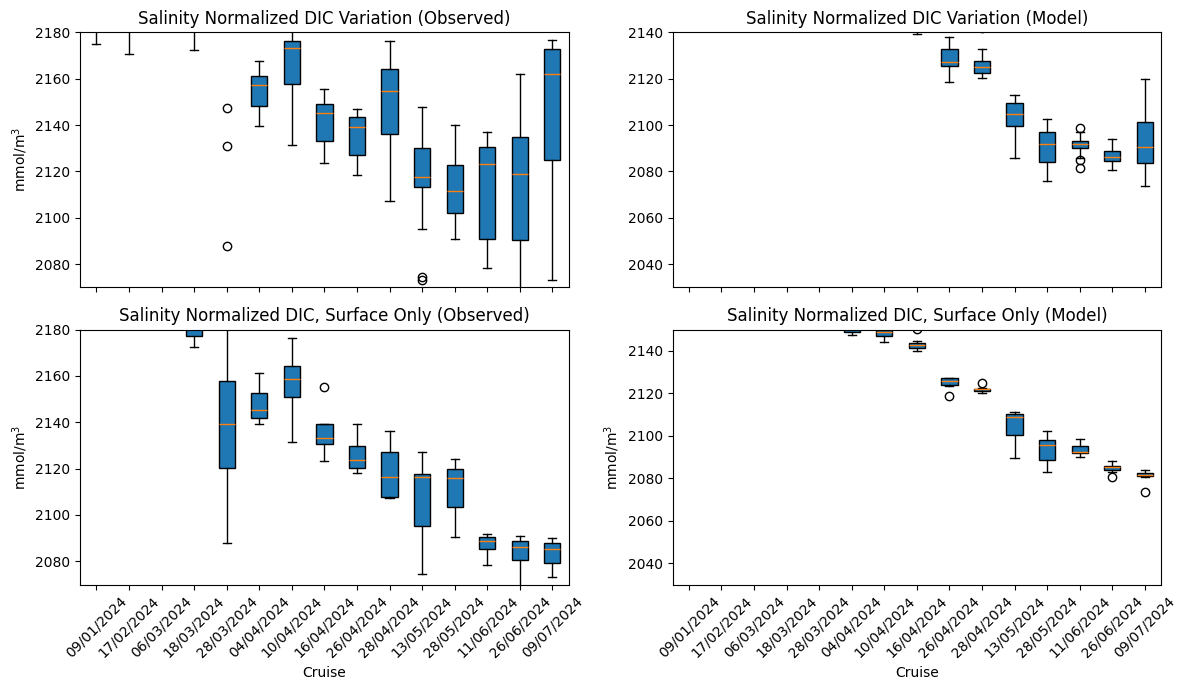

In [22]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Define depth levels
levels = np.arange(0, 80)

# Create figure and subplots (3 rows: 1 for the map, 2 for boxplots)
fig = plt.figure(figsize=(12, 7))  # Wider figure for side-by-side plots
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1], width_ratios=[1, 1])  



# --- Function for Extracting Data ---
def extract_cruise_data(var, depth=None, num_cruises=15):
    """Extracts non-NaN values for a given variable across cruises."""
    cruises = []
    for i in range(num_cruises):
        data = np.hstack(var.isel(time=i) if depth is None else var.isel(time=i, depth_bin=depth))
        cruises.append(data[~np.isnan(data)])
    return cruises

def extract_model_data(var, depth=None, num_cruises=15):
    """Extracts non-NaN values from the model across time steps."""
    cruises = []
    for i in range(num_cruises):
        data = np.hstack(var.isel(time=i) if depth is None else var.isel(time=i, depth=depth))
        cruises.append(data[~np.isnan(data)])
    return cruises

# --- Boxplots for Observations (Left) and Model (Right) ---
ax_obs = fig.add_subplot(gs[0, 0])  # Observations
ax_model = fig.add_subplot(gs[0, 1])  # Model

ax_obs.boxplot(extract_cruise_data(obs['nDIC']), patch_artist=True)
ax_obs.set_title('Salinity Normalized DIC Variation (Observed)')
ax_obs.set_ylabel('mmol/m$^3$')
ax_obs.set_xticklabels([])
ax_obs.set_ylim(2070,2180)

ax_model.boxplot(extract_model_data(bgc_sub['nDIC']), patch_artist=True)
ax_model.set_title('Salinity Normalized DIC Variation (Model)')
ax_model.set_xticklabels([])
ax_model.set_ylim(2030,2140)

# --- Surface-Only Boxplots for Observations (Left) and Model (Right) ---
ax_obs_surface = fig.add_subplot(gs[1, 0])  # Observations (Surface)
ax_model_surface = fig.add_subplot(gs[1, 1])  # Model (Surface)

ax_obs_surface.boxplot(extract_cruise_data(obs['nDIC'], depth=0), patch_artist=True)
ax_obs_surface.set_title('Salinity Normalized DIC, Surface Only (Observed)')
ax_obs_surface.set_xlabel('Cruise')
ax_obs_surface.set_ylabel('mmol/m$^3$')
ax_obs_surface.set_xticklabels(pd.to_datetime(obs['time'].isel(time=slice(0,15))).strftime('%d/%m/%Y'), rotation=45)
ax_obs_surface.set_ylim(2070,2180)

ax_model_surface.boxplot(extract_model_data(bgc_sub['nDIC'], depth=0), patch_artist=True)
ax_model_surface.set_title('Salinity Normalized DIC, Surface Only (Model)')
ax_model_surface.set_xlabel('Cruise')
ax_model_surface.set_ylabel('mmol/m$^3$')
ax_model_surface.set_xticklabels(pd.to_datetime(bgc_sub['time'].isel(time=slice(0,15))).strftime('%d/%m/%Y'), rotation=45)
ax_model_surface.set_ylim()
ax_model_surface.set_ylim(2030,2150)

plt.tight_layout()
plt.show()


## Along-fjord alkalinity sections

Observed salinity-normalized alkalinity (left) and alkalinity (right) at stations HV1, HV5, HV9 and HV10, averaged over the first 10 observation dates and plotted against station longitude and depth bin.

Text(0, 0.5, 'depth (m)')

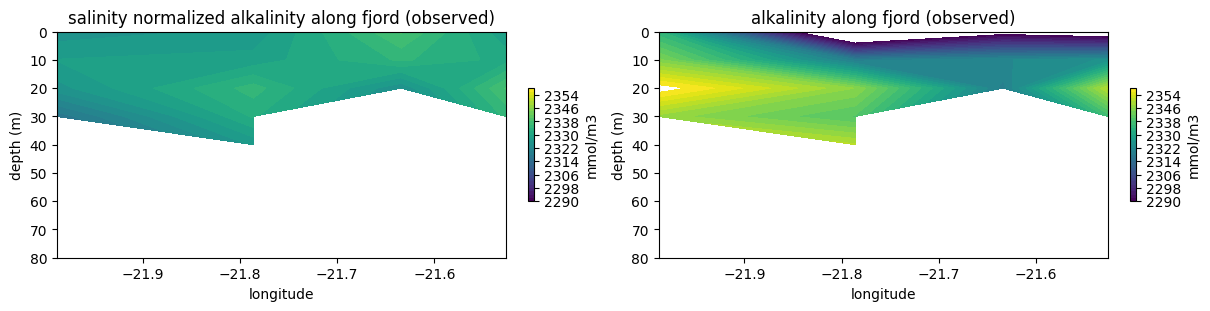

In [23]:
loc = obs['lon'].sel(HV=[1,5,9,10]).isel(depth_bin=0).mean('time').values
depth=obs['depth_bin'].values
levels=np.arange(2290,2360,2)

bins = np.arange(0, 90, 10) 
#depth_bins = xr.DataArray(pd.cut(depth, bins, labels=bins[:-1]), dims="depth", name="binned_depth")

data_alk1=obs['nTA'].sel(HV=[1,5,9,10]).isel(time=slice(0,10)).mean('time')
data_alk2=obs['Alk_qc'].sel(HV=[1,5,9,10]).isel(time=slice(0,10)).mean('time')

fig, axarr = plt.subplots(nrows=1, ncols=2, figsize=(6*2, 3), constrained_layout=True)
ax = axarr.flatten()

#c0=ax[0].contourf(loc, data_alk.depth, data_alk.transpose())
c0=ax[0].contourf(loc,data_alk1.depth_bin,data_alk1.transpose(),levels)
plt.colorbar(c0,ax=ax[0], orientation='vertical', label='mmol/m3',shrink=0.5)
ax[0].invert_yaxis()
ax[0].set_title('salinity normalized alkalinity along fjord (observed)')
ax[0].set_xlabel('longitude')
ax[0].set_ylabel('depth (m)')

c0=ax[1].contourf(loc,data_alk2.depth_bin,data_alk2.transpose(),levels)
plt.colorbar(c0,ax=ax[1], orientation='vertical', label='mmol/m3',shrink=0.5)
ax[1].invert_yaxis()
ax[1].set_title('alkalinity along fjord (observed)')
ax[1].set_xlabel('longitude')
ax[1].set_ylabel('depth (m)')

### Modeled alkalinity sections

The same sections from the model (`nTA` and `ALK` in `bgc_sub`), averaged over observation-date indices 2–6. The colour levels (2230–2300 mmol m$^{-3}$) are lower than those of the observed sections (2290–2360 mmol m$^{-3}$).

Text(0, 0.5, 'depth (m)')

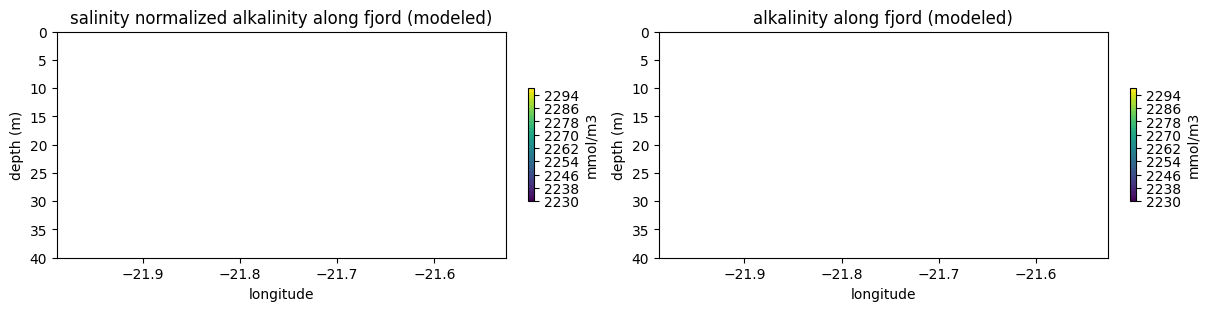

In [24]:
loc = obs['lon'].sel(HV=[1,5,9,10]).isel(depth_bin=0).mean('time').values
depth=obs['depth_bin'].values
levels=np.arange(2230,2300,2)

bins = np.arange(0, 90, 10) 
#depth_bins = xr.DataArray(pd.cut(depth, bins, labels=bins[:-1]), dims="depth", name="binned_depth")

data_alk1=bgc_sub['nTA'].sel(location=[1,5,9,10]).isel(time=slice(2,7)).mean('time')
data_alk2=bgc_sub['ALK'].sel(location=[1,5,9,10]).isel(time=slice(2,7)).mean('time')

fig, axarr = plt.subplots(nrows=1, ncols=2, figsize=(6*2, 3), constrained_layout=True)
ax = axarr.flatten()

#c0=ax[0].contourf(loc, data_alk.depth, data_alk.transpose())
c0=ax[0].contourf(loc,data_alk1.depth*(-1),data_alk1.transpose(),levels)
plt.colorbar(c0,ax=ax[0], orientation='vertical', label='mmol/m3',shrink=0.5)
ax[0].set_ylim(0,40)
ax[0].invert_yaxis()
ax[0].set_title('salinity normalized alkalinity along fjord (modeled)')
ax[0].set_xlabel('longitude')
ax[0].set_ylabel('depth (m)')


c0=ax[1].contourf(loc,data_alk2.depth*(-1),data_alk2.transpose(),levels)
plt.colorbar(c0,ax=ax[1], orientation='vertical', label='mmol/m3',shrink=0.5)
ax[1].set_ylim(0,40)
ax[1].invert_yaxis()
ax[1].set_title('alkalinity along fjord (modeled)')
ax[1].set_xlabel('longitude')
ax[1].set_ylabel('depth (m)')

## Mean vertical profiles of DIC and alkalinity

Mean ± one standard deviation profiles over stations HV1, HV5, HV9 and HV10, observed (orange) and modeled (black, grey shading). The first cell shows salinity-normalized DIC (panel c) and DIC (panel d) for May–August.

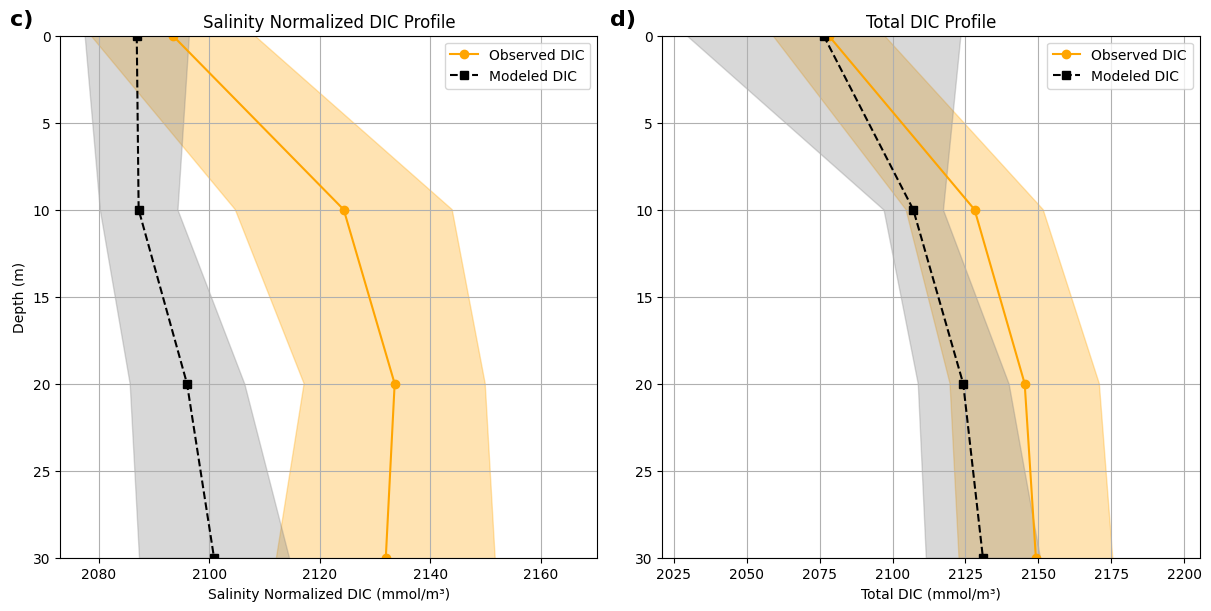

In [40]:
import matplotlib.pyplot as plt
import numpy as np

# Compute mean and standard deviation over time for observations
depth_obs = obs['depth_bin'].values
depth_model = bgc_sub['depth'].values

# Observations (Mean and Std Dev)
alk_mean_obs = obs['DIC_qc'].sel(HV=[1,5,9,10]).isel(time=slice(0,15)).mean(dim=['time', 'HV'])
alk_std_obs = obs['DIC_qc'].sel(HV=[1,5,9,10]).isel(time=slice(0,15)).std(dim=['time', 'HV'])

nalk_mean_obs = obs['nDIC'].sel(HV=[1,5,9,10]).isel(time=slice(0,10)).mean(dim=['time', 'HV'])
nalk_std_obs = obs['nDIC'].sel(HV=[1,5,9,10]).isel(time=slice(0,10)).std(dim=['time', 'HV'])

# Model (Mean and Std Dev)
alk_mean_model = bgc_sub['DIC'].sel(location=[1,5,9,10]).isel(time=slice(2,7)).mean(dim=['time', 'location'])
alk_std_model = bgc_sub['DIC'].sel(location=[1,5,9,10]).isel(time=slice(2,7)).std(dim=['time', 'location'])

nalk_mean_model = bgc_sub['nDIC'].sel(location=[1,5,9,10]).isel(time=slice(2,7)).mean(dim=['time', 'location'])
nalk_std_model = bgc_sub['nDIC'].sel(location=[1,5,9,10]).isel(time=slice(2,7)).std(dim=['time', 'location'])


# -----------------------------
# Define month mask (April–September)
# -----------------------------
obs_month_mask = obs['time'].dt.month.isin([5, 6, 7, 8])
mod_month_mask = bgc_sub['time'].dt.month.isin([5, 6, 7, 8])

# -----------------------------
# Observations (Mean and Std Dev)
# -----------------------------
alk_mean_obs = obs['DIC_qc'].sel(HV=[1,5,9,10]).where(obs_month_mask, drop=True).mean(dim=['time', 'HV'])
alk_std_obs  = obs['DIC_qc'].sel(HV=[1,5,9,10]).where(obs_month_mask, drop=True).std(dim=['time', 'HV'])

nalk_mean_obs = obs['nDIC'].sel(HV=[1,5,9,10]).where(obs_month_mask, drop=True).mean(dim=['time', 'HV'])
nalk_std_obs  = obs['nDIC'].sel(HV=[1,5,9,10]).where(obs_month_mask, drop=True).std(dim=['time', 'HV'])

# -----------------------------
# Model (Mean and Std Dev)
# -----------------------------
alk_mean_model = bgc_sub['DIC'].sel(location=[1,5,9,10]).where(mod_month_mask, drop=True).mean(dim=['time', 'location'])
alk_std_model  = bgc_sub['DIC'].sel(location=[1,5,9,10]).where(mod_month_mask, drop=True).std(dim=['time', 'location'])

nalk_mean_model = bgc_sub['nDIC'].sel(location=[1,5,9,10]).where(mod_month_mask, drop=True).mean(dim=['time', 'location'])
nalk_std_model  = bgc_sub['nDIC'].sel(location=[1,5,9,10]).where(mod_month_mask, drop=True).std(dim=['time', 'location'])

# Create figure with 2 columns (nTA on left, TA on right)
fig, axarr = plt.subplots(nrows=1, ncols=2, figsize=(12, 6), constrained_layout=True)
ax = axarr.flatten()

# --- Plot Salinity Normalized DIC (nTA) ---
ax[0].plot(
    nalk_mean_obs, depth_obs,
    marker='o', linestyle='-',
    color='orange', label='Observed DIC'
)
ax[0].fill_betweenx(
    depth_obs,
    nalk_mean_obs - nalk_std_obs,
    nalk_mean_obs + nalk_std_obs,
    color='orange', alpha=0.3
)

ax[0].plot(
    nalk_mean_model, depth_model * (-1),
    marker='s', linestyle='--',
    color='black', label='Modeled DIC'
)
ax[0].fill_betweenx(
    depth_model * (-1),
    nalk_mean_model - nalk_std_model,
    nalk_mean_model + nalk_std_model,
    color='grey', alpha=0.3
)

ax[0].set_ylim(0, 30)
ax[0].invert_yaxis()
ax[0].set_xlabel('Salinity Normalized DIC (mmol/m³)')
ax[0].set_ylabel('Depth (m)')
ax[0].set_title('Salinity Normalized DIC Profile')
ax[0].legend()
ax[0].grid()


# --- Plot Total DIC ---
ax[1].plot(
    alk_mean_obs, depth_obs,
    marker='o', linestyle='-',
    color='orange', label='Observed DIC'
)
ax[1].fill_betweenx(
    depth_obs,
    alk_mean_obs - alk_std_obs,
    alk_mean_obs + alk_std_obs,
    color='orange', alpha=0.3
)

ax[1].plot(
    alk_mean_model, depth_model * (-1),
    marker='s', linestyle='--',
    color='black', label='Modeled DIC'
)
ax[1].fill_betweenx(
    depth_model * (-1),
    alk_mean_model - alk_std_model,
    alk_mean_model + alk_std_model,
    color='grey', alpha=0.3
)

ax[1].set_ylim(0, 30)
ax[1].invert_yaxis()
ax[1].set_xlabel('Total DIC (mmol/m³)')
ax[1].set_title('Total DIC Profile')
ax[1].legend()
ax[1].grid()

# Label c)
ax[0].text(-0.05, 1.05, 'c)', transform=ax[0].transAxes, 
           fontsize=16, fontweight='bold', va='top', ha='right')
# Label d)
ax[1].text(-0.05, 1.05, 'd)', transform=ax[1].transAxes, 
           fontsize=16, fontweight='bold', va='top', ha='right')

plt.show()


### Alkalinity profiles

The same profiles for salinity-normalized alkalinity (panel a) and alkalinity (panel b), for April–September 2024.

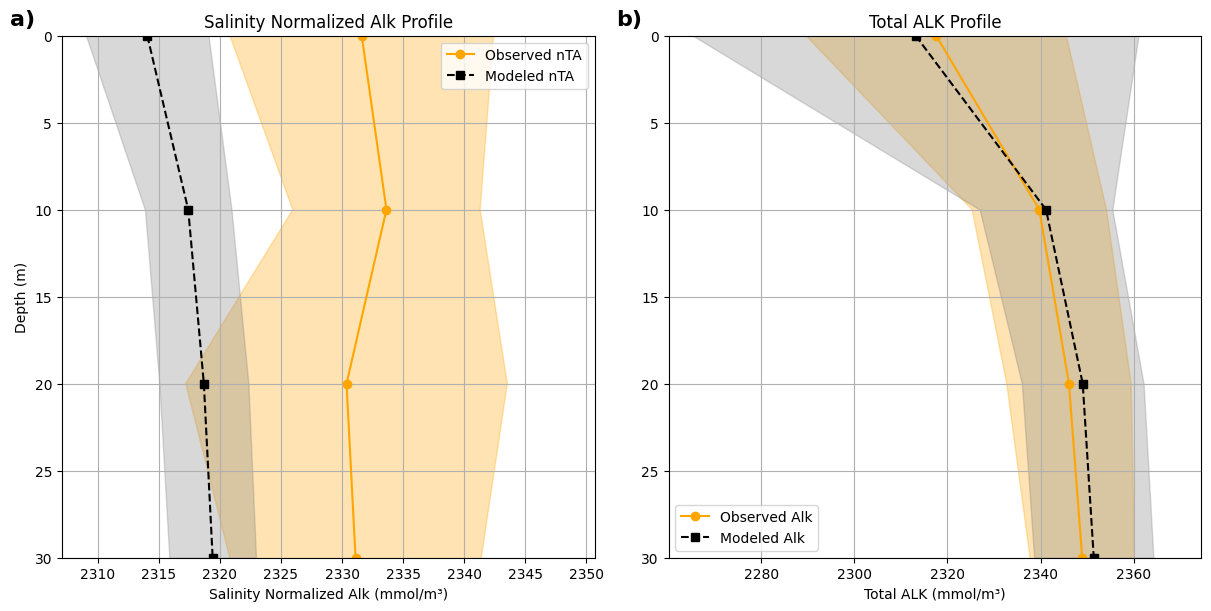

In [39]:
import matplotlib.pyplot as plt
import numpy as np

# Compute mean and standard deviation over time for observations
depth_obs = obs['depth_bin'].values
depth_model = bgc_sub['depth'].values

# --- Define Masks for Time Filtering ---
obs_month_mask = (obs['time'].dt.year == 2024) & (
    obs['time'].dt.month.isin([4, 5, 6, 7, 8, 9])
)

mod_month_mask = (bgc_sub['time'].dt.year == 2024) & (
    bgc_sub['time'].dt.month.isin([4, 5, 6, 7, 8, 9])
)

# -----------------------------
# Observations (Mean and Std Dev)
# -----------------------------
alk_mean_obs = (
    obs['Alk_qc']
    .sel(HV=[1, 5, 9, 10])
    .where(obs_month_mask, drop=True)
    .mean(dim=['time', 'HV'])
)
alk_std_obs = (
    obs['Alk_qc']
    .sel(HV=[1, 5, 9, 10])
    .where(obs_month_mask, drop=True)
    .std(dim=['time', 'HV'])
)

nalk_mean_obs = (
    obs['nTA']
    .sel(HV=[1, 5, 9, 10])
    .where(obs_month_mask, drop=True)
    .mean(dim=['time', 'HV'])
)
nalk_std_obs = (
    obs['nTA']
    .sel(HV=[1, 5, 9, 10])
    .where(obs_month_mask, drop=True)
    .std(dim=['time', 'HV'])
)

# -----------------------------
# Model (Mean and Std Dev)
# -----------------------------
alk_mean_model = (
    bgc_sub['ALK']
    .sel(location=[1, 5, 9, 10])
    .where(mod_month_mask, drop=True)
    .mean(dim=['time', 'location'])
)
alk_std_model = (
    bgc_sub['ALK']
    .sel(location=[1, 5, 9, 10])
    .where(mod_month_mask, drop=True)
    .std(dim=['time', 'location'])
)

nalk_mean_model = (
    bgc_sub['nTA']
    .sel(location=[1, 5, 9, 10])
    .where(mod_month_mask, drop=True)
    .mean(dim=['time', 'location'])
)
nalk_std_model = (
    bgc_sub['nTA']
    .sel(location=[1, 5, 9, 10])
    .where(mod_month_mask, drop=True)
    .std(dim=['time', 'location'])
)


# Create figure with 2 columns (nTA on left, TA on right)
fig, axarr = plt.subplots(
    nrows=1, ncols=2, figsize=(12, 6), constrained_layout=True
)
ax = axarr.flatten()

# --- Plot Salinity Normalized DIC (nTA) ---
ax[0].plot(
    nalk_mean_obs,
    depth_obs,
    marker='o',
    linestyle='-',
    color='orange',
    label='Observed nTA',
)
ax[0].fill_betweenx(
    depth_obs,
    nalk_mean_obs - nalk_std_obs,
    nalk_mean_obs + nalk_std_obs,
    color='orange',
    alpha=0.3,
)

ax[0].plot(
    nalk_mean_model,
    depth_model * (-1),
    marker='s',
    linestyle='--',
    color='black',
    label='Modeled nTA',
)
ax[0].fill_betweenx(
    depth_model * (-1),
    nalk_mean_model - nalk_std_model,
    nalk_mean_model + nalk_std_model,
    color='grey',
    alpha=0.3,
)

ax[0].set_ylim(0, 30)
ax[0].invert_yaxis()
ax[0].set_xlabel('Salinity Normalized Alk (mmol/m³)')
ax[0].set_ylabel('Depth (m)')
ax[0].set_title('Salinity Normalized Alk Profile')
ax[0].legend()
ax[0].grid()


# --- Plot Total DIC ---
ax[1].plot(
    alk_mean_obs,
    depth_obs,
    marker='o',
    linestyle='-',
    color='orange',
    label='Observed Alk',
)
ax[1].fill_betweenx(
    depth_obs,
    alk_mean_obs - alk_std_obs,
    alk_mean_obs + alk_std_obs,
    color='orange',
    alpha=0.3,
)

ax[1].plot(
    alk_mean_model,
    depth_model * (-1),
    marker='s',
    linestyle='--',
    color='black',
    label='Modeled Alk',
)
ax[1].fill_betweenx(
    depth_model * (-1),
    alk_mean_model - alk_std_model,
    alk_mean_model + alk_std_model,
    color='grey',
    alpha=0.3,
)

ax[1].set_ylim(0, 30)
ax[1].invert_yaxis()
ax[1].set_xlabel('Total ALK (mmol/m³)')
ax[1].set_title('Total ALK Profile')
ax[1].legend()
ax[1].grid()

# Label a)
ax[0].text(
    -0.05,
    1.05,
    'a)',
    transform=ax[0].transAxes,
    fontsize=16,
    fontweight='bold',
    va='top',
    ha='right',
)
# Label b)
ax[1].text(
    -0.05,
    1.05,
    'b)',
    transform=ax[1].transAxes,
    fontsize=16,
    fontweight='bold',
    va='top',
    ha='right',
)

plt.show()

## Surface alkalinity and DIC around Iceland (UNIFIED BGC dataset)

Maps of surface `Alk` and `DIC` from `/anvil/projects/x-ees250129/Datasets/UNIFIED/BGCdataset.nc` for 60–68°N, 32–10°W. The alkalinity panel shows index 0 and the DIC panel index 6 of the leading dimension of the surface fields.

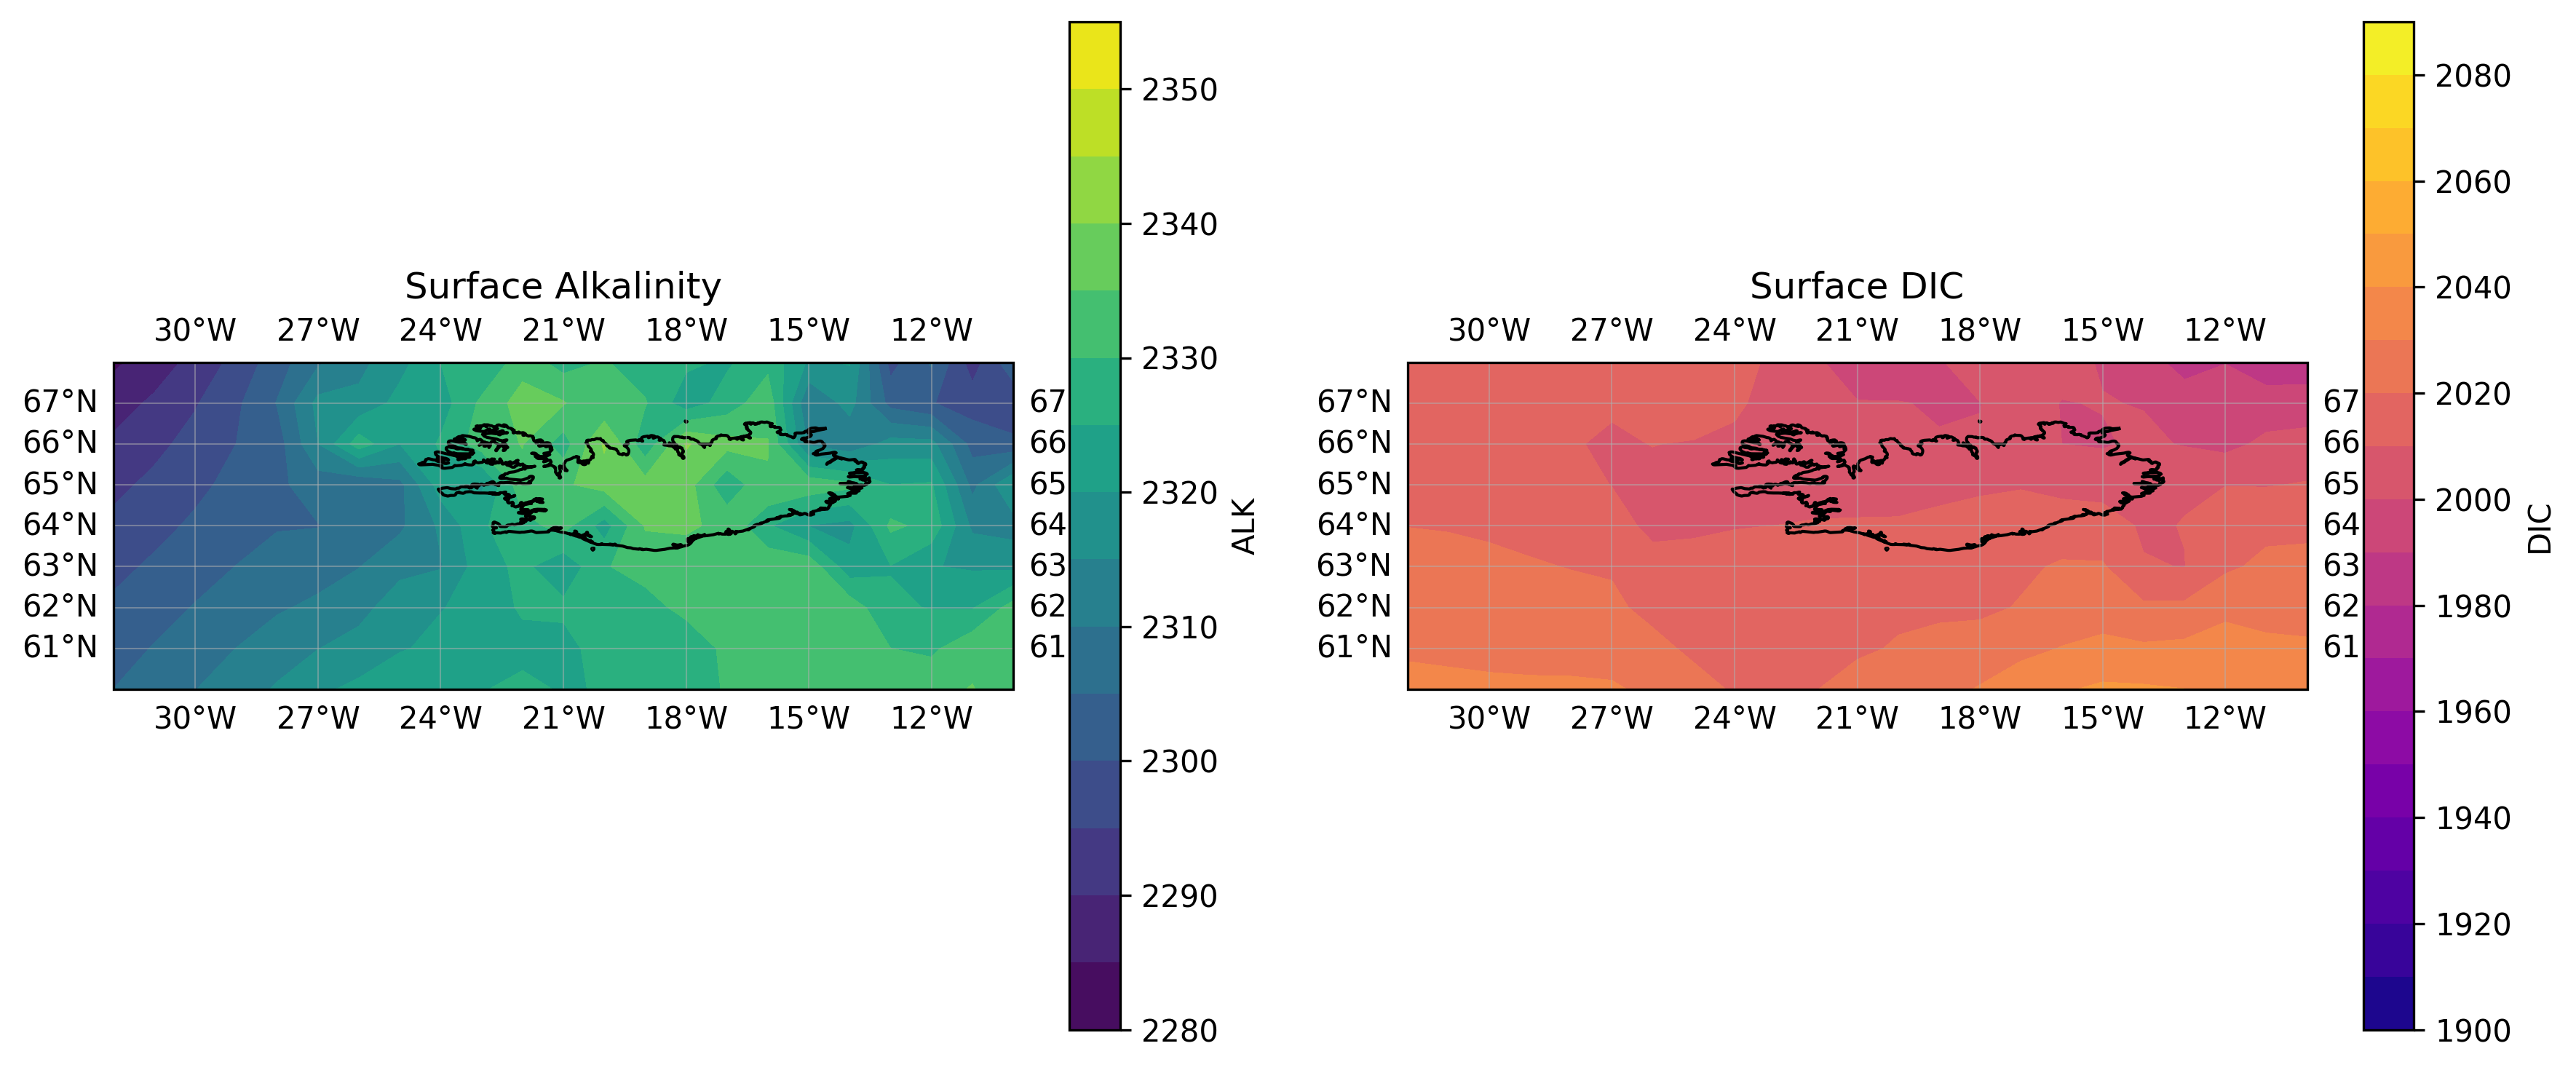

In [27]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# --------------------------------------------------
# Open dataset
# --------------------------------------------------
ds = xr.open_dataset(
    "/anvil/projects/x-ees250129/Datasets/UNIFIED/BGCdataset.nc"
)

# --------------------------------------------------
# Select surface layer
# --------------------------------------------------
if "dep" in ds.dims:
    Alk_surf = ds["Alk"].isel(dep=0)
    DIC_surf = ds["DIC"].isel(dep=0)
elif "z" in ds.dims:
    Alk_surf = ds["Alk"].isel(z=0)
    DIC_surf = ds["DIC"].isel(z=0)
else:
    raise ValueError("No recognized vertical dimension found.")

# --------------------------------------------------
# Coordinates
# --------------------------------------------------
lat = ds["lat"]
lon = ds["lon"]

# --------------------------------------------------
# Plot
# --------------------------------------------------
fig, axs = plt.subplots(
    ncols=2,
    figsize=(12, 5),
    subplot_kw={"projection": ccrs.PlateCarree()},
    dpi=300
)

# ---- ALK ----
cf1 = axs[0].contourf(
    lon, lat, Alk_surf[0, :, :],
    levels=np.arange(2280,2360,5),
    cmap="viridis",
    transform=ccrs.PlateCarree()
)
axs[0].set_title("Surface Alkalinity")
plt.colorbar(cf1, ax=axs[0], orientation="vertical", label="ALK")

# ---- DIC ----
cf2 = axs[1].contourf(
    lon, lat, DIC_surf[6, :, :],
    levels=np.arange(1900,2100,10),
    cmap="plasma",
    transform=ccrs.PlateCarree()
)
axs[1].set_title("Surface DIC")
plt.colorbar(cf2, ax=axs[1], orientation="vertical", label="DIC")

# --------------------------------------------------
# Zoom to Iceland
# --------------------------------------------------
# (SW Iceland–centered, but includes whole island)
lon_min, lon_max = -32, -10
lat_min, lat_max = 60, 68

for ax in axs:
    ax.set_extent([lon_min, lon_max, lat_min, lat_max],
                  crs=ccrs.PlateCarree())
    ax.coastlines(resolution="10m")
    ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)

plt.tight_layout()
plt.show()


## Along-fjord salinity-normalized DIC sections

Observed salinity-normalized DIC at stations HV1, HV5, HV9 and HV10, averaged over observation-date indices 0–3 (titled April–May) and 5–9 (titled June–August).

Text(0, 0.5, 'depth (m)')

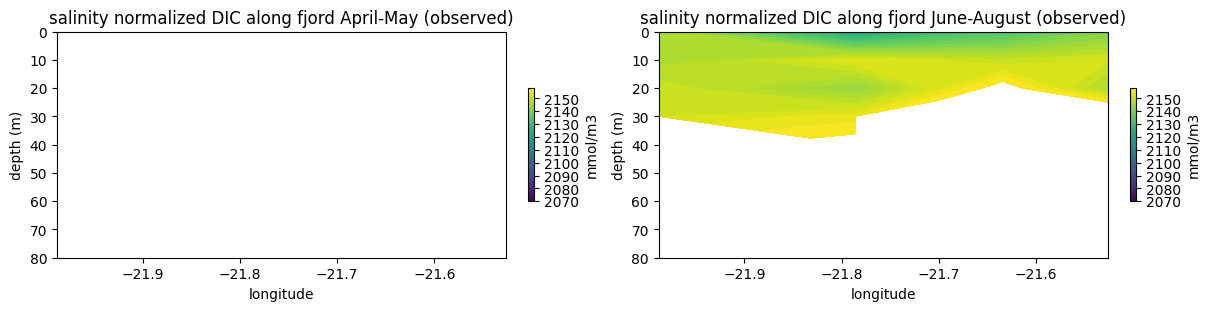

In [28]:
loc = obs['lon'].sel(HV=[1,5,9,10]).isel(depth_bin=0).mean('time').values
depth=obs['depth_bin'].values
levels=np.arange(2070,2160,2)

bins = np.arange(0, 90, 10) 
#depth_bins = xr.DataArray(pd.cut(depth, bins, labels=bins[:-1]), dims="depth", name="binned_depth")

data_alk1=obs['nDIC'].sel(HV=[1,5,9,10]).isel(time=slice(0,4)).mean('time')
data_alk2=obs['nDIC'].sel(HV=[1,5,9,10]).isel(time=slice(5,10)).mean('time')

fig, axarr = plt.subplots(nrows=1, ncols=2, figsize=(6*2, 3), constrained_layout=True)
ax = axarr.flatten()

#c0=ax[0].contourf(loc, data_alk.depth, data_alk.transpose())
c0=ax[0].contourf(loc,data_alk1.depth_bin,data_alk1.transpose(),levels)
plt.colorbar(c0,ax=ax[0], orientation='vertical', label='mmol/m3',shrink=0.5)
ax[0].invert_yaxis()
ax[0].set_title('salinity normalized DIC along fjord April-May (observed)')
ax[0].set_xlabel('longitude')
ax[0].set_ylabel('depth (m)')

c0=ax[1].contourf(loc,data_alk2.depth_bin,data_alk2.transpose(),levels)
plt.colorbar(c0,ax=ax[1], orientation='vertical', label='mmol/m3',shrink=0.5)
ax[1].invert_yaxis()
ax[1].set_title('salinity normalized DIC along fjord June-August (observed)')
ax[1].set_xlabel('longitude')
ax[1].set_ylabel('depth (m)')

### Modeled DIC sections

The same sections from the model (`nDIC` in `bgc_sub`), using the same date indices and colour levels.

Text(0, 0.5, 'depth (m)')

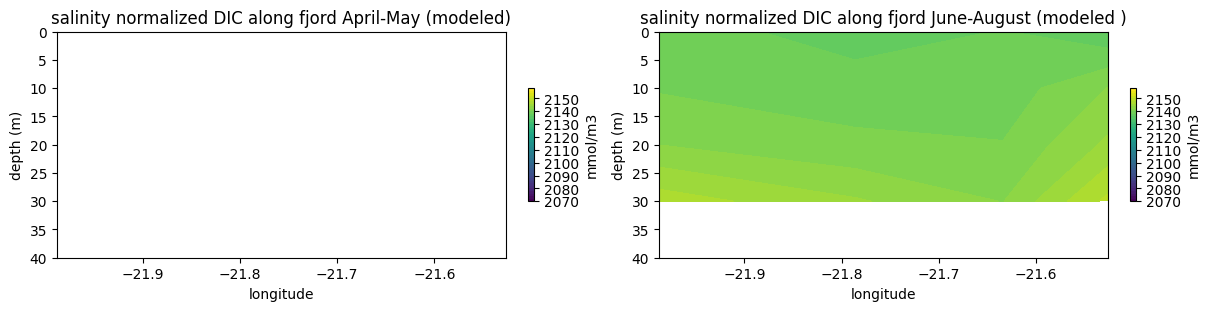

In [29]:
loc = obs['lon'].sel(HV=[1,5,9,10]).isel(depth_bin=0).mean('time').values
depth=obs['depth_bin'].values
levels=np.arange(2070,2160,2)

bins = np.arange(0, 90, 10) 
#depth_bins = xr.DataArray(pd.cut(depth, bins, labels=bins[:-1]), dims="depth", name="binned_depth")

data_alk1=obs['nDIC'].sel(HV=[1,5,9,10]).isel(time=slice(0,4)).mean('time')
data_alk2=obs['nDIC'].sel(HV=[1,5,9,10]).isel(time=slice(5,10)).mean('time')

data_alk1=bgc_sub['nDIC'].sel(location=[1,5,9,10]).isel(time=slice(0,4)).mean('time')
data_alk2=bgc_sub['nDIC'].sel(location=[1,5,9,10]).isel(time=slice(5,10)).mean('time')


fig, axarr = plt.subplots(nrows=1, ncols=2, figsize=(6*2, 3), constrained_layout=True)
ax = axarr.flatten()

#c0=ax[0].contourf(loc, data_alk.depth, data_alk.transpose())
c0=ax[0].contourf(loc,data_alk1.depth*(-1),data_alk1.transpose(),levels)
plt.colorbar(c0,ax=ax[0], orientation='vertical', label='mmol/m3',shrink=0.5)
ax[0].set_ylim(0,40)
ax[0].invert_yaxis()
ax[0].set_title('salinity normalized DIC along fjord April-May (modeled)')
ax[0].set_xlabel('longitude')
ax[0].set_ylabel('depth (m)')

c0=ax[1].contourf(loc,data_alk2.depth*(-1),data_alk2.transpose(),levels)
plt.colorbar(c0,ax=ax[1], orientation='vertical', label='mmol/m3',shrink=0.5)
ax[1].set_ylim(0,40)
ax[1].invert_yaxis()
ax[1].set_title('salinity normalized DIC along fjord June-August (modeled )')
ax[1].set_xlabel('longitude')
ax[1].set_ylabel('depth (m)')

## Layer-averaged time series of salinity-normalized DIC and alkalinity

Station-averaged salinity-normalized DIC (top) and alkalinity (bottom) for the 0–10 m and 20–40 m layers, as labelled in the legends, observed (left) and modeled (right).

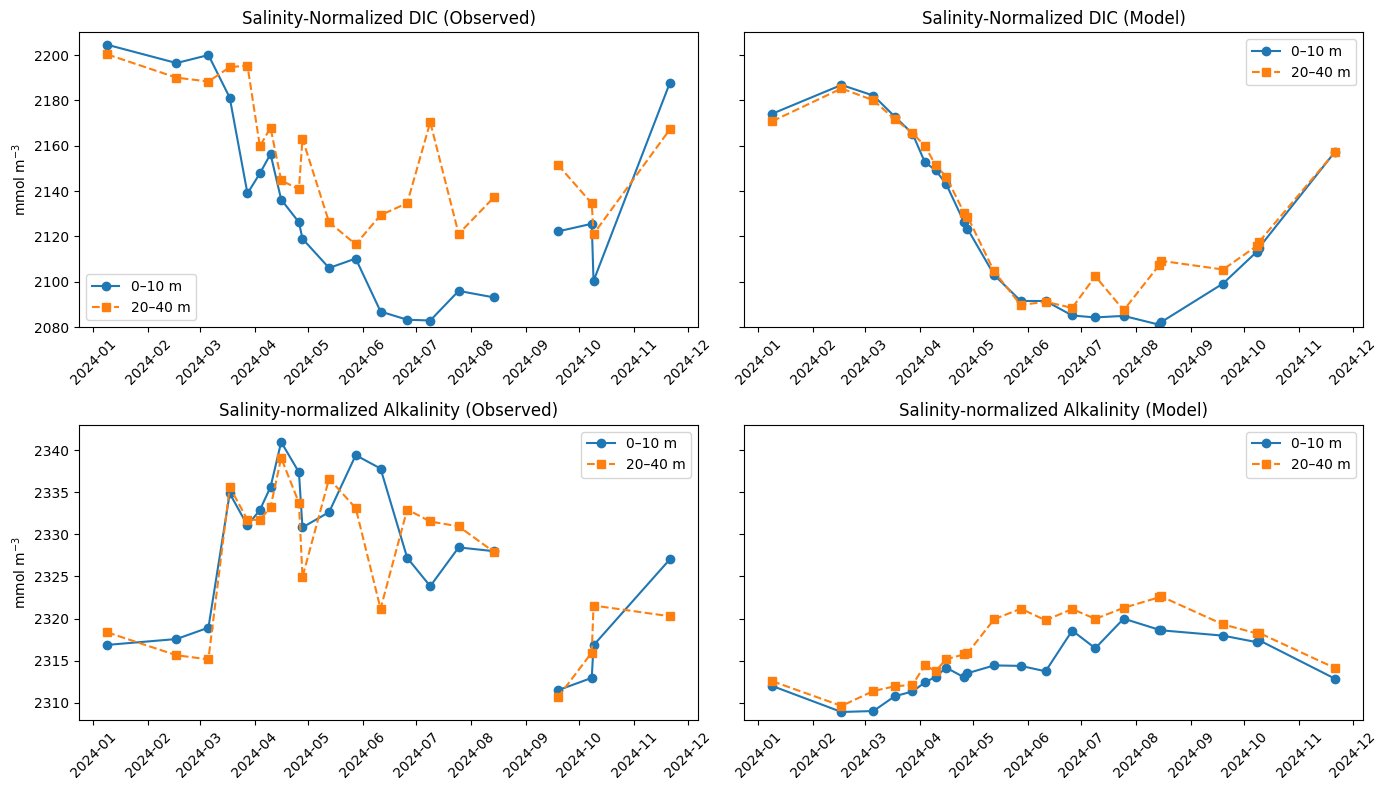

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Create figure and subplots (2x2), sharing y-axis per row
fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(14, 8), sharex=False, sharey='row'
)

# --- Data Extraction Functions ---
def extract_depth_avg(var, depth_range):
    """Extract mean across depth range for each time step (observations)."""
    return var.sel(depth_bin=slice(*depth_range)).mean(dim='depth_bin', skipna=True)

def extract_depth_avg_model(var, depth_range):
    """Extract mean across depth range for each time step (model)."""
    return var.sel(depth=slice(*depth_range)).mean(dim='depth', skipna=True)

# --- Depth ranges ---
upper_depth_range = (0, 5)
lower_depth_range = (20, 40)

upper_depth_range_m = (-0, -10)
lower_depth_range_m = (-20, -40)

# =======================
# TOP ROW — nDIC (Limits: 2080 to 2210)
# =======================

# --- Observed nDIC ---
ax = axes[0, 0]
obs_upper = extract_depth_avg(obs['nDIC'].mean('HV'), upper_depth_range)
obs_lower = extract_depth_avg(obs['nDIC'].mean('HV'), lower_depth_range)

ax.plot(obs['time'], obs_upper, label='0–10 m', marker='o')
ax.plot(obs['time'], obs_lower, label='20–40 m', marker='s', linestyle='--')
ax.set_title('Salinity-Normalized DIC (Observed)')
ax.set_ylabel('mmol m$^{-3}$')
ax.set_ylim(2080, 2210)
ax.legend()
ax.tick_params(axis='x', rotation=45)

# --- Modeled nDIC ---
ax = axes[0, 1]
model_upper = extract_depth_avg_model(
    bgc_sub['nDIC'].mean('location'), upper_depth_range_m
)
model_lower = extract_depth_avg_model(
    bgc_sub['nDIC'].mean('location'), lower_depth_range_m
)

ax.plot(bgc_sub['time'], model_upper, label='0–10 m', marker='o')
ax.plot(bgc_sub['time'], model_lower, label='20–40 m', marker='s', linestyle='--')
ax.set_title('Salinity-Normalized DIC (Model)')
ax.set_ylim(2080, 2210)
ax.legend()
ax.tick_params(axis='x', rotation=45)

# =======================
# BOTTOM ROW — ALK (Limits: 2308 to 2343)
# =======================

# --- Observed ALK ---
ax = axes[1, 0]
obs_upper = extract_depth_avg(obs['nTA'].mean('HV'), upper_depth_range)
obs_lower = extract_depth_avg(obs['nTA'].mean('HV'), lower_depth_range)

ax.plot(obs['time'], obs_upper, label='0–10 m', marker='o')
ax.plot(obs['time'], obs_lower, label='20–40 m', marker='s', linestyle='--')
ax.set_title('Salinity-normalized Alkalinity (Observed)')
ax.set_ylabel('mmol m$^{-3}$')
ax.set_ylim(2308, 2343)
ax.legend()
ax.tick_params(axis='x', rotation=45)

# --- Modeled ALK ---
ax = axes[1, 1]
model_upper = extract_depth_avg_model(
    bgc_sub['nTA'].mean('location'), upper_depth_range_m
)
model_lower = extract_depth_avg_model(
    bgc_sub['nTA'].mean('location'), lower_depth_range_m
)

ax.plot(bgc_sub['time'], model_upper, label='0–10 m', marker='o')
ax.plot(bgc_sub['time'], model_lower, label='20–40 m', marker='s', linestyle='--')
ax.set_title('Salinity-normalized Alkalinity (Model)')
ax.set_ylim(2308, 2343)
ax.legend()
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Surface nutrients by cruise

Boxplots of surface nitrate + nitrite, phosphate, silicate and ammonium for each of the first 22 observation dates. Observations (left) are restricted to QC flag 2; the model panels (right) show `NO3`, `PO4`, `SiO3` and `NH4`.

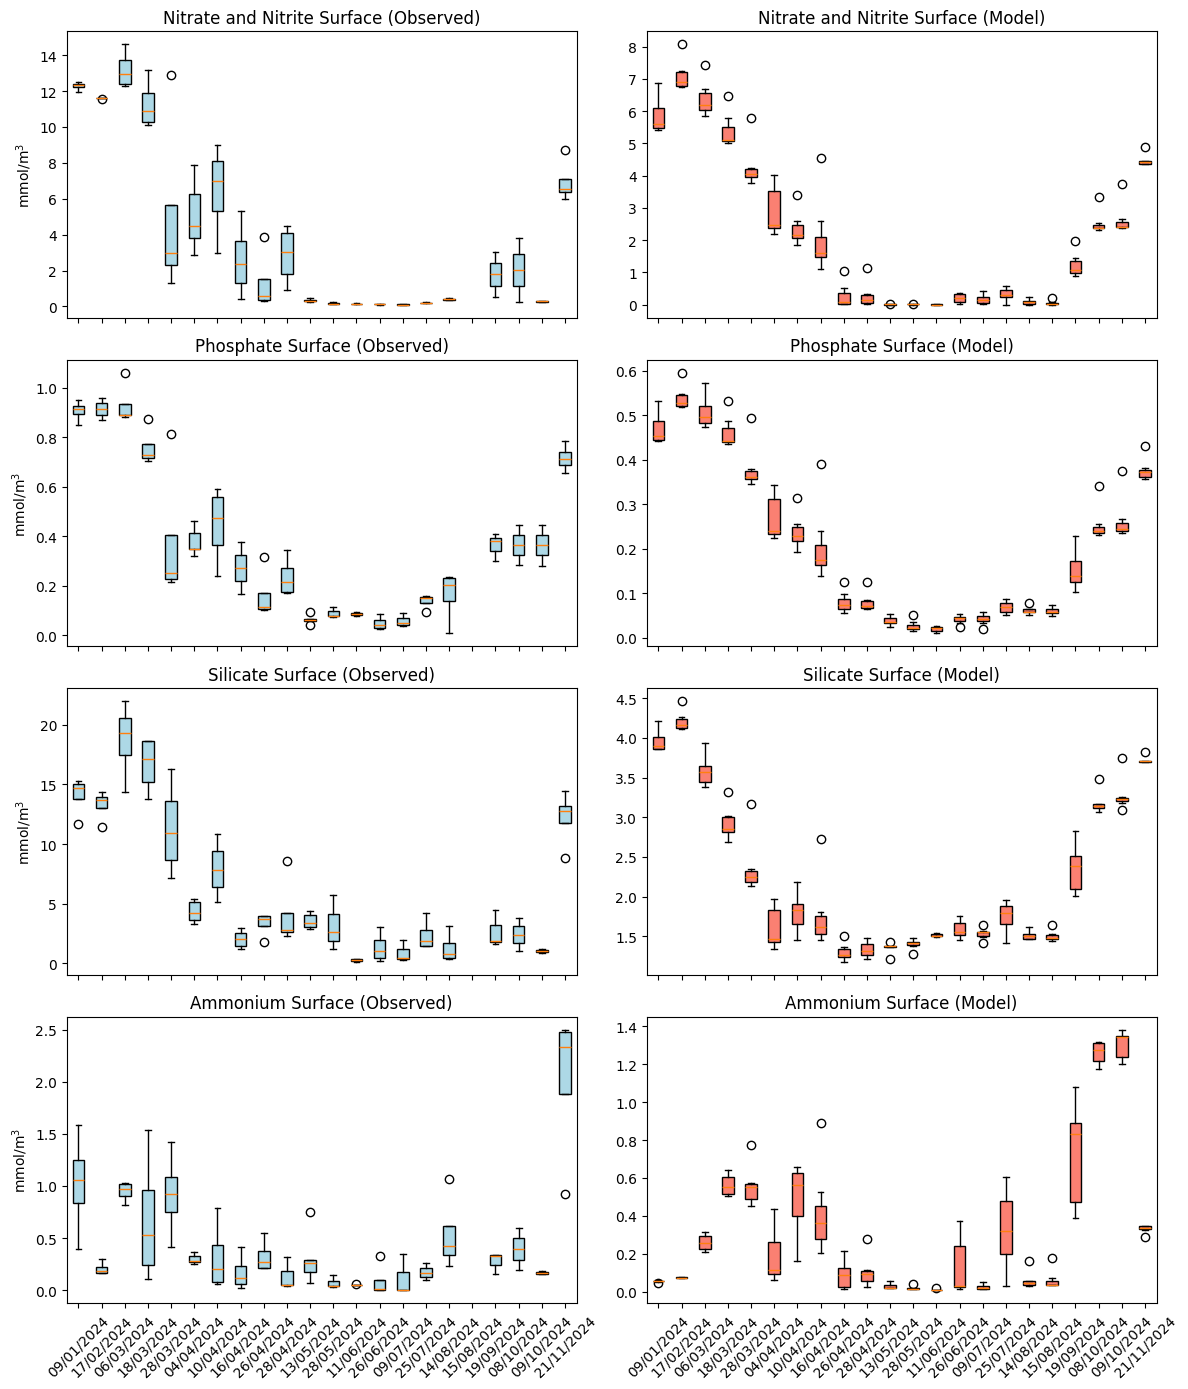

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Configuration ---
# Match the 'variables' list EXACTLY to the names in your Data variables list
variables = ['Nitrate_and_Nitrite', 'Phosphate', 'Silicate', 'Ammonium']

# --- Refactored Extraction Functions ---
def extract_cruise_data(ds, var_name, depth_idx=0, num_cruises=22):
    """Filters by flag == 2 and extracts values using exact depth_bin index."""
    cruises = []
    
    # Dynamically find the flag column (e.g., 'Phosphate_flag')
    flag_col = f"{var_name}_flag"
    
    # Check if the flag column exists to prevent a new KeyError
    if flag_col in ds.data_vars:
        filtered_data = ds[var_name].where(ds[flag_col] == 2)
    else:
        # Fallback if no flag is found
        filtered_data = ds[var_name]
    
    for i in range(num_cruises):
        # Select by the position in the depth dimension
        data = np.hstack(filtered_data.isel(time=i, depth_bin=depth_idx))
        cruises.append(data[~np.isnan(data)])
    return cruises

def extract_model_data(var, depth_idx=0, num_cruises=22):
    """Extracts model data using exact depth index."""
    cruises = []
    for i in range(num_cruises):
        data = np.hstack(var.isel(time=i, depth=depth_idx))
        cruises.append(data[~np.isnan(data)])
    return cruises

# --- Plotting ---
fig = plt.figure(figsize=(12, 14))
gs = fig.add_gridspec(4, 2, height_ratios=[1, 1, 1, 1], width_ratios=[1, 1])

for row, var in enumerate(variables):
    # --- Observations (Left) ---
    ax_obs = fig.add_subplot(gs[row, 0])
    obs_data = extract_cruise_data(obs, var, depth_idx=0)
    ax_obs.boxplot(obs_data, patch_artist=True, boxprops=dict(facecolor='lightblue'))
    
    # Replace underscores with spaces for cleaner titles
    display_name = var.replace('_', ' ')
    ax_obs.set_title(f'{display_name} Surface (Observed)')
    ax_obs.set_ylabel('mmol/m$^3$')
    
    # --- Model (Right) ---
    ax_model = fig.add_subplot(gs[row, 1])
    
    # Match model names to observation names
    # Mapping Silicate (Obs) -> SiO3 (Model) and Nitrate_and_Nitrite (Obs) -> NO3 (Model)
    model_map = {
        'Silicate': 'SiO3',
        'Nitrate_and_Nitrite': 'NO3',
        'Phosphate': 'PO4',
        'Ammonium': 'NH4'
    }
    model_key = model_map.get(var, var)
    
    mod_data = extract_model_data(bgc_sub[model_key], depth_idx=0)
    ax_model.boxplot(mod_data, patch_artist=True, boxprops=dict(facecolor='salmon'))
    ax_model.set_title(f'{display_name} Surface (Model)')

    # --- X-Axis Labels ---
    if row == 3:
        date_labels = pd.to_datetime(obs['time'].isel(time=slice(0, 22))).strftime('%d/%m/%Y')
        ax_obs.set_xticklabels(date_labels, rotation=45)
        ax_model.set_xticklabels(date_labels, rotation=45)
    else:
        ax_obs.set_xticklabels([])
        ax_model.set_xticklabels([])

plt.tight_layout()
plt.show()

### Surface nutrients by cruise, second version

The same comparison as the previous figure, written out panel by panel and without box colours.

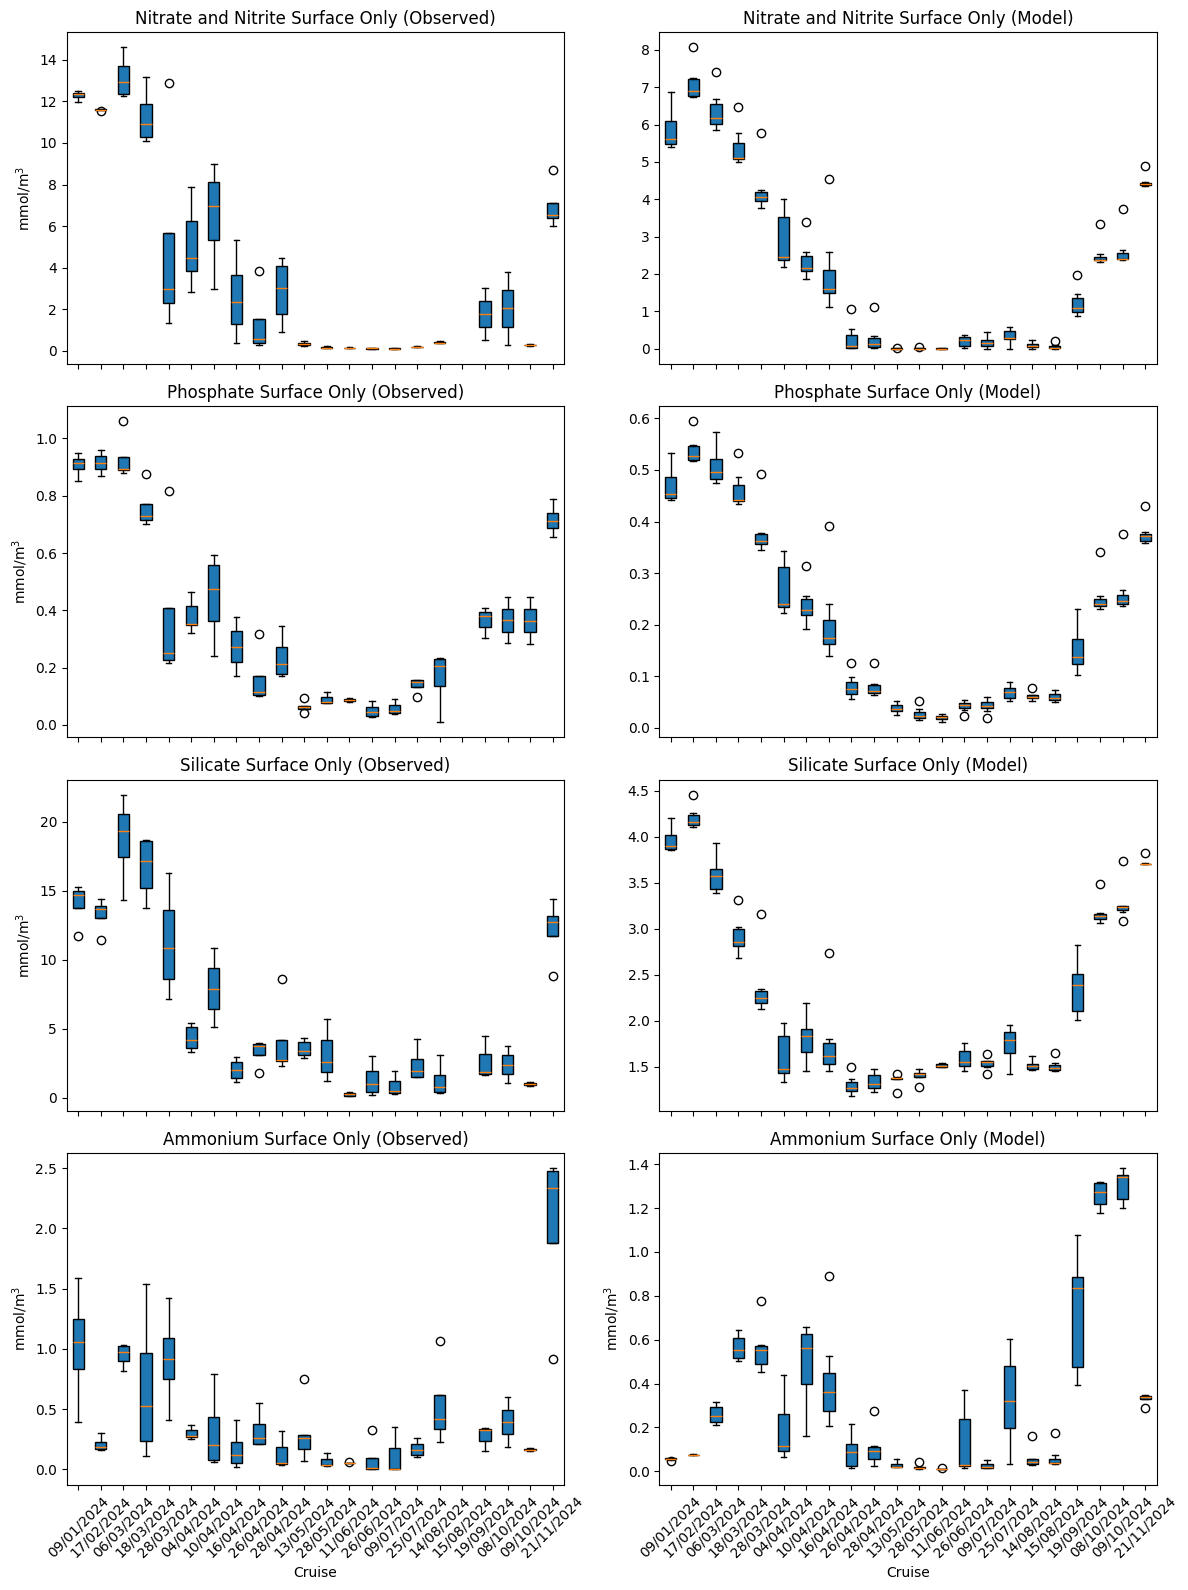

In [33]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Create figure and subplots
fig = plt.figure(figsize=(12, 16)) 
gs = fig.add_gridspec(4, 2, height_ratios=[1, 1, 1, 1], width_ratios=[1, 1])  

# --- Refactored Data Extraction Functions ---
def extract_cruise_data(ds, var_name, depth_bin=0, num_cruises=22):
    """Filters by flag == 2 and extracts values using exact depth_bin index."""
    cruises = []
    
    # Identify the flag variable (e.g., 'Nitrate_and_Nitrite_flag')
    flag_col = f"{var_name}_flag"
    
    # Filter for Flag == 2 (Good Data)
    filtered_var = ds[var_name].where(ds[flag_col] == 2)
    
    for i in range(num_cruises):
        # Using .isel(time=i) because your metadata showed 'time' is the dimension name
        data = np.hstack(filtered_var.isel(time=i, depth_bin=depth_bin))
        cruises.append(data[~np.isnan(data)])
    return cruises

def extract_model_data(var, depth=0, num_cruises=22):
    """Extracts non-NaN values from the model across time steps."""
    cruises = []
    for i in range(num_cruises):
        data = np.hstack(var.isel(time=i, depth=depth))
        cruises.append(data[~np.isnan(data)])
    return cruises

# --- Nitrate and Nitrite (NO3/NO2) Boxplots ---
ax1_obs = fig.add_subplot(gs[0, 0])
ax1_model = fig.add_subplot(gs[0, 1])

ax1_obs.boxplot(extract_cruise_data(obs, 'Nitrate_and_Nitrite'), patch_artist=True)
ax1_obs.set_title('Nitrate and Nitrite Surface Only (Observed)')
ax1_obs.set_ylabel('mmol/m$^3$')
ax1_obs.set_xticklabels([])

ax1_model.boxplot(extract_model_data(bgc_sub['NO3']), patch_artist=True)
ax1_model.set_title('Nitrate and Nitrite Surface Only (Model)')
ax1_model.set_xticklabels([])

# --- Phosphate (PO4) Boxplots ---
ax2_obs = fig.add_subplot(gs[1, 0])
ax2_model = fig.add_subplot(gs[1, 1])

ax2_obs.boxplot(extract_cruise_data(obs, 'Phosphate'), patch_artist=True)
ax2_obs.set_title('Phosphate Surface Only (Observed)')
ax2_obs.set_ylabel('mmol/m$^3$')
ax2_obs.set_xticklabels([])

ax2_model.boxplot(extract_model_data(bgc_sub['PO4']), patch_artist=True)
ax2_model.set_title('Phosphate Surface Only (Model)')
ax2_model.set_xticklabels([])

# --- Silicate (SiO2) Boxplots ---
ax3_obs = fig.add_subplot(gs[2, 0])
ax3_model = fig.add_subplot(gs[2, 1])

ax3_obs.boxplot(extract_cruise_data(obs, 'Silicate'), patch_artist=True)
ax3_obs.set_title('Silicate Surface Only (Observed)')
ax3_obs.set_ylabel('mmol/m$^3$')
ax3_obs.set_xticklabels([])

ax3_model.boxplot(extract_model_data(bgc_sub['SiO3']), patch_artist=True)
ax3_model.set_title('Silicate Surface Only (Model)')
ax3_model.set_xticklabels([])

# --- Ammonium (NH4) Boxplots ---
ax4_obs = fig.add_subplot(gs[3, 0])
ax4_model = fig.add_subplot(gs[3, 1])

ax4_obs.boxplot(extract_cruise_data(obs, 'Ammonium'), patch_artist=True)
ax4_obs.set_title('Ammonium Surface Only (Observed)')
ax4_obs.set_xlabel('Cruise')
ax4_obs.set_ylabel('mmol/m$^3$')

# Use 22 cruises for labels as per your request
labels = pd.to_datetime(obs['time'].isel(time=slice(0, 22))).strftime('%d/%m/%Y')
ax4_obs.set_xticklabels(labels, rotation=45)

ax4_model.boxplot(extract_model_data(bgc_sub['NH4']), patch_artist=True)
ax4_model.set_title('Ammonium Surface Only (Model)')
ax4_model.set_xlabel('Cruise')
ax4_model.set_ylabel('mmol/m$^3$')
ax4_model.set_xticklabels(labels, rotation=45)

plt.tight_layout()
plt.show()

## Nutrients over the full water column by cruise

As above, but each box contains all depth bins (observations, QC flag 2) or all model depth levels for each of the first 22 observation dates.

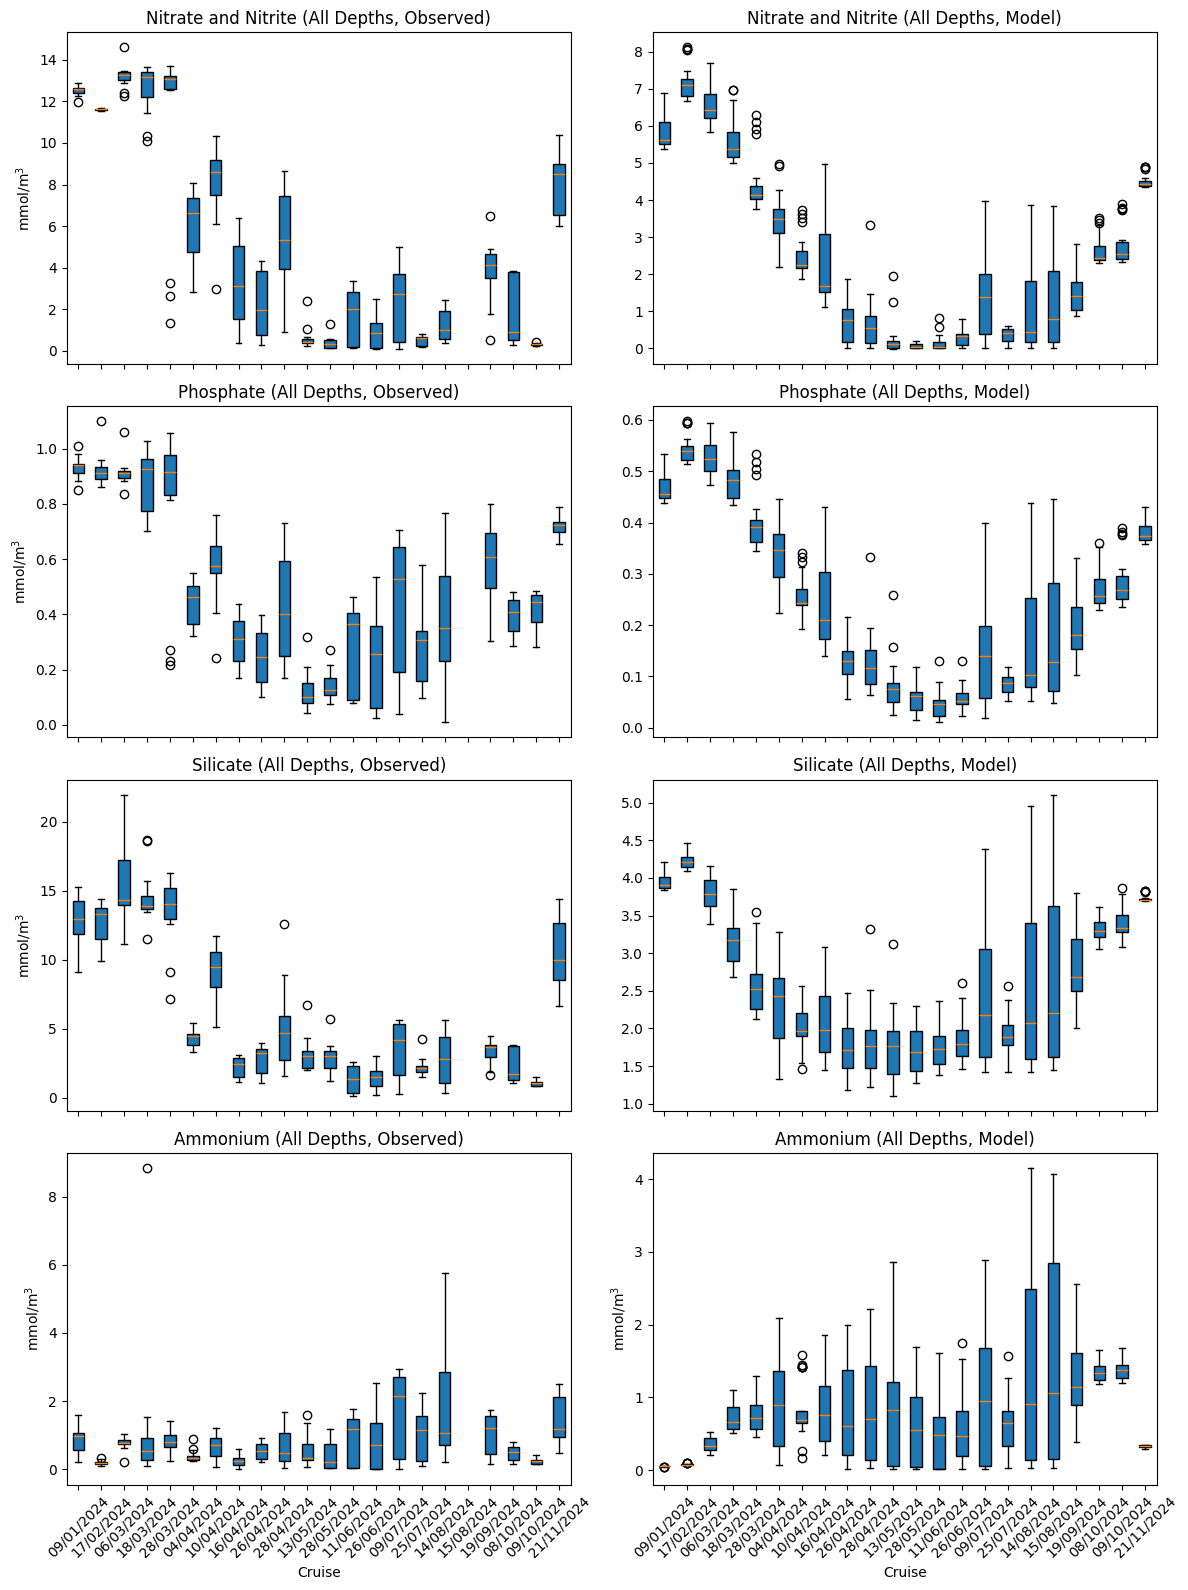

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Create figure and subplots
fig = plt.figure(figsize=(12, 16))
gs = fig.add_gridspec(4, 2, height_ratios=[1, 1, 1, 1], width_ratios=[1, 1])  

# --- Refactored Data Extraction Functions ---
def extract_cruise_data_all_depths(ds, var_name, num_cruises=22):
    """Filters by flag == 2 and extracts values for all depths across cruises."""
    cruises = []
    
    # Identify the flag variable (e.g., 'Silicate_flag')
    flag_col = f"{var_name}_flag"
    
    # Apply Quality Flag 2 Filter
    filtered_var = ds[var_name].where(ds[flag_col] == 2)
    
    for i in range(num_cruises):
        # By not specifying depth_bin, we get the whole water column for that time step
        data = np.hstack(filtered_var.isel(time=i))
        cruises.append(data[~np.isnan(data)])
    return cruises

def extract_model_data_all_depths(var, num_cruises=22):
    """Extracts all depth levels from the model across time steps."""
    cruises = []
    for i in range(num_cruises):
        data = np.hstack(var.isel(time=i))
        cruises.append(data[~np.isnan(data)])
    return cruises

# --- Nitrate and Nitrite (Nitrate_and_Nitrite) ---
ax1_obs = fig.add_subplot(gs[0, 0])
ax1_model = fig.add_subplot(gs[0, 1])

ax1_obs.boxplot(extract_cruise_data_all_depths(obs, 'Nitrate_and_Nitrite'), patch_artist=True)
ax1_obs.set_title('Nitrate and Nitrite (All Depths, Observed)')
ax1_obs.set_ylabel('mmol/m$^3$')
ax1_obs.set_xticklabels([])

ax1_model.boxplot(extract_model_data_all_depths(bgc_sub['NO3']), patch_artist=True)
ax1_model.set_title('Nitrate and Nitrite (All Depths, Model)')
ax1_model.set_xticklabels([])

# --- Phosphate (Phosphate) ---
ax2_obs = fig.add_subplot(gs[1, 0])
ax2_model = fig.add_subplot(gs[1, 1])

ax2_obs.boxplot(extract_cruise_data_all_depths(obs, 'Phosphate'), patch_artist=True)
ax2_obs.set_title('Phosphate (All Depths, Observed)')
ax2_obs.set_ylabel('mmol/m$^3$')
ax2_obs.set_xticklabels([])

ax2_model.boxplot(extract_model_data_all_depths(bgc_sub['PO4']), patch_artist=True)
ax2_model.set_title('Phosphate (All Depths, Model)')
ax2_model.set_xticklabels([])

# --- Silicate (Silicate) ---
ax3_obs = fig.add_subplot(gs[2, 0])
ax3_model = fig.add_subplot(gs[2, 1])

ax3_obs.boxplot(extract_cruise_data_all_depths(obs, 'Silicate'), patch_artist=True)
ax3_obs.set_title('Silicate (All Depths, Observed)')
ax3_obs.set_ylabel('mmol/m$^3$')
ax3_obs.set_xticklabels([])

ax3_model.boxplot(extract_model_data_all_depths(bgc_sub['SiO3']), patch_artist=True)
ax3_model.set_title('Silicate (All Depths, Model)')
ax3_model.set_xticklabels([])

# --- Ammonium (Ammonium) ---
ax4_obs = fig.add_subplot(gs[3, 0])
ax4_model = fig.add_subplot(gs[3, 1])

ax4_obs.boxplot(extract_cruise_data_all_depths(obs, 'Ammonium'), patch_artist=True)
ax4_obs.set_title('Ammonium (All Depths, Observed)')
ax4_obs.set_xlabel('Cruise')
ax4_obs.set_ylabel('mmol/m$^3$')

# Use common time labels from the obs dataset
labels = pd.to_datetime(obs['time'].isel(time=slice(0, 22))).strftime('%d/%m/%Y')
ax4_obs.set_xticklabels(labels, rotation=45)

ax4_model.boxplot(extract_model_data_all_depths(bgc_sub['NH4']), patch_artist=True)
ax4_model.set_title('Ammonium (All Depths, Model)')
ax4_model.set_xlabel('Cruise')
ax4_model.set_ylabel('mmol/m$^3$')
ax4_model.set_xticklabels(labels, rotation=45)

plt.tight_layout()
plt.show()

## Layer-averaged nutrient time series

Station-averaged nitrate + nitrite, phosphate, silicate and ammonium for the 0–10 m and 20–40 m layers, as labelled in the legends, in 2024, observed (left, QC flag 2) and modeled (right). Each model panel uses the y-limits of the corresponding observed panel.

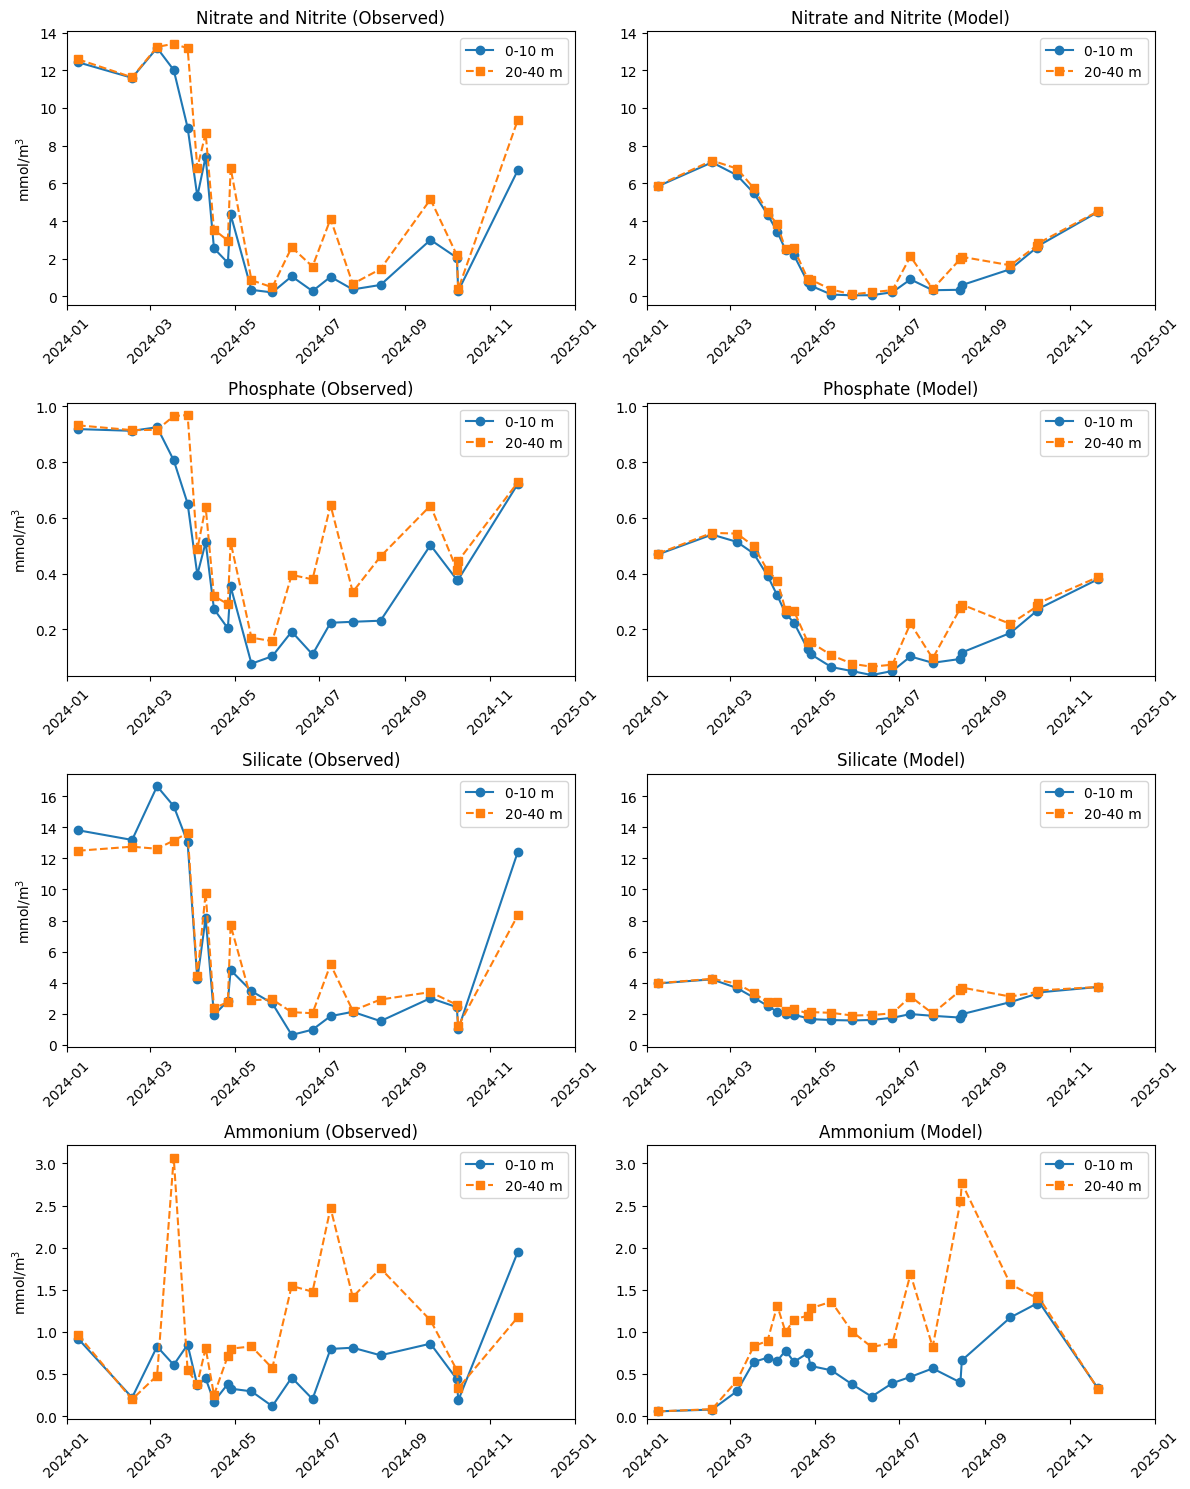

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Create figure and subplots
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(12, 15), sharex=False)  

# --- Refactored Data Extraction Functions ---
def extract_depth_avg_obs(ds, var_name, depth_range):
    """Filters by flag == 2 and averages across a depth range (observed)."""
    flag_col = f"{var_name}_flag"
    
    # Filter for Flag == 2 (Good Data) and average over stations (HV)
    filtered_var = ds[var_name].where(ds[flag_col] == 2).mean('HV', skipna=True)
    
    # Select the depth range using the depth_bin dimension
    return filtered_var.sel(depth_bin=slice(*depth_range)).mean(dim='depth_bin', skipna=True)

def extract_depth_avg_model(var, depth_range):
    """Averages across model location and depth range."""
    # Average across location (12 stations) and depth slice
    return var.mean('location', skipna=True).sel(depth=slice(*depth_range)).mean(dim='depth', skipna=True)

# Define depth ranges (adjusting indices for depth_bin if necessary)
upper_depth_range = (0, 10)   
lower_depth_range = (20, 40) 

# Model depth ranges (assuming negative values for depth axis)
upper_depth_range_m = (-0.5, -10)
lower_depth_range_m = (-20, -40)

# Define mapping for matching Model keys to Observation keys
nutrient_map = [
    {'obs': 'Nitrate_and_Nitrite', 'model': 'NO3', 'title': 'Nitrate and Nitrite'},
    {'obs': 'Phosphate',           'model': 'PO4', 'title': 'Phosphate'},
    {'obs': 'Silicate',            'model': 'SiO3', 'title': 'Silicate'},
    {'obs': 'Ammonium',            'model': 'NH4', 'title': 'Ammonium'}
]

# --- Plotting ---
for i, nut in enumerate(nutrient_map):
    # --- Observations (Column 0) ---
    ax_obs = axes[i, 0]
    
    obs_upper = extract_depth_avg_obs(obs, nut['obs'], upper_depth_range)
    obs_lower = extract_depth_avg_obs(obs, nut['obs'], lower_depth_range)

    # Filter NaNs for Upper
    mask_u = np.isfinite(obs_upper)
    ax_obs.plot(obs['time'][mask_u], obs_upper[mask_u], 
                label='0-10 m', marker='o', linestyle='-')
    
    # Filter NaNs for Lower
    mask_l = np.isfinite(obs_lower)
    ax_obs.plot(obs['time'][mask_l], obs_lower[mask_l], 
                label='20-40 m', marker='s', linestyle='--')
    
    ax_obs.set_title(f"{nut['title']} (Observed)")
    ax_obs.set_ylabel('mmol/m$^3$')
    ax_obs.legend()
    ax_obs.tick_params(axis='x', rotation=45)
    ax_obs.set_xlim([pd.Timestamp('2024-01-01'),
                 pd.Timestamp('2025-01-01')])
    # --- Determine observed y-limits ---
    ymin = np.nanmin([obs_upper.min().item(), obs_lower.min().item()])
    ymax = np.nanmax([obs_upper.max().item(), obs_lower.max().item()])

    # Add small padding
    yrange = ymax - ymin
    ymin -= 0.05 * yrange
    ymax += 0.05 * yrange

    # --- Model (Column 1) ---
    ax_model = axes[i, 1]
    
    model_upper = extract_depth_avg_model(bgc_sub[nut['model']], upper_depth_range_m)
    model_lower = extract_depth_avg_model(bgc_sub[nut['model']], lower_depth_range_m)

    # Filter NaNs for Model Upper
    m_mask_u = np.isfinite(model_upper)
    ax_model.plot(bgc_sub['time'][m_mask_u], model_upper[m_mask_u], 
                  label='0-10 m', marker='o', linestyle='-')
    
    # Filter NaNs for Model Lower
    m_mask_l = np.isfinite(model_lower)
    ax_model.plot(bgc_sub['time'][m_mask_l], model_lower[m_mask_l], 
                  label='20-40 m', marker='s', linestyle='--')
    
    ax_model.set_title(f"{nut['title']} (Model)")
    ax_model.legend()
    ax_model.tick_params(axis='x', rotation=45)
    ax_model.set_xlim([pd.Timestamp('2024-01-01'),
                 pd.Timestamp('2025-01-01')])

    ax_model.set_ylim(ymin, ymax)

plt.tight_layout()
plt.show()

## Chlorophyll, nutrient and iron time series

Station-averaged surface and deep time series for 2024: chlorophyll (observed `chl_a`, no QC flag applied; modeled `spChl` + `diatChl`), the four nutrients, and modeled iron (`Fe`, no observations). The layer depth ranges are set in the cell and differ between observations and model.

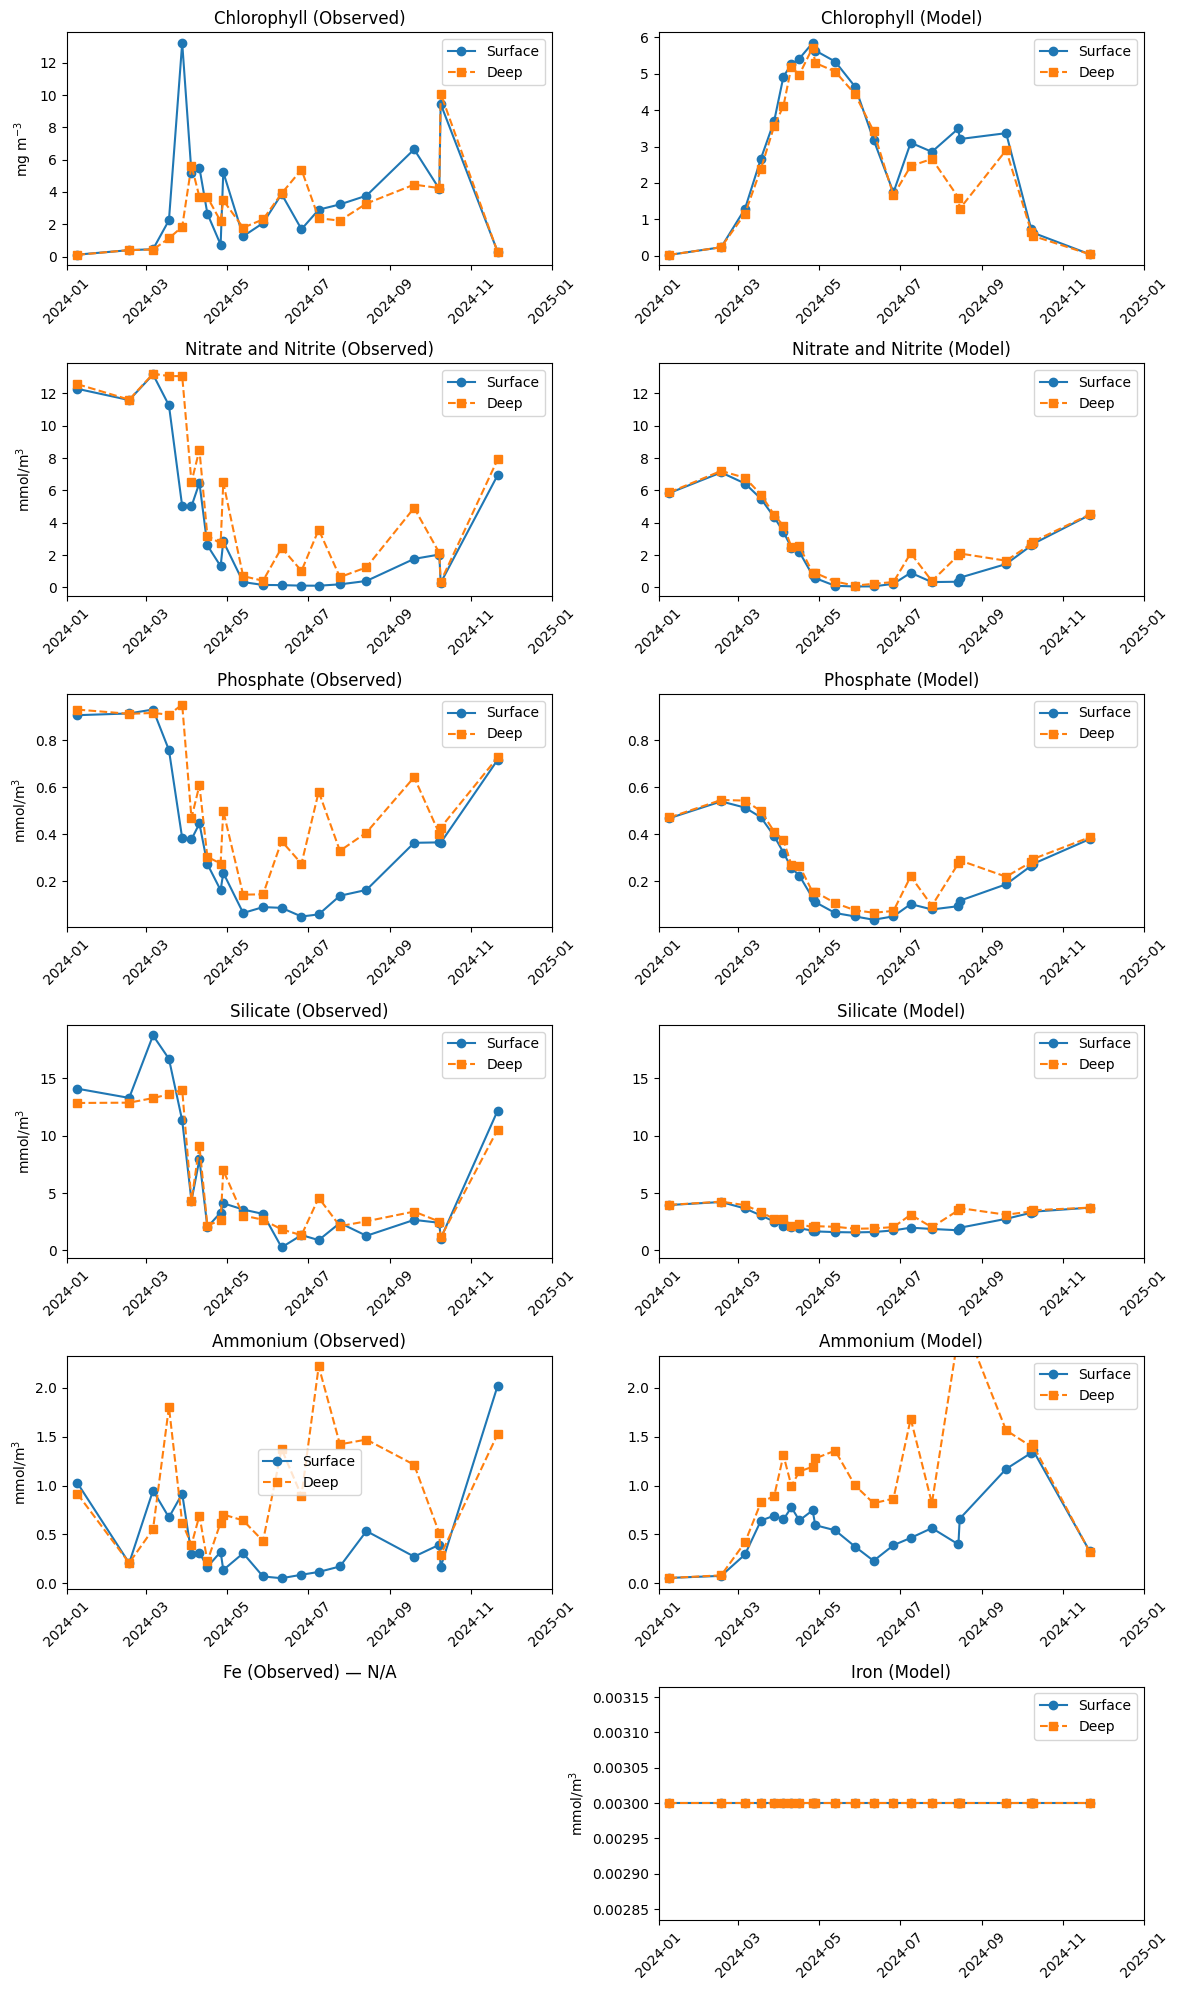

In [36]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# =========================
# Figure (NOW 6 ROWS)
# =========================
fig, axes = plt.subplots(nrows=6, ncols=2, figsize=(12, 20), sharex=False)

# =========================
# Helper functions (unchanged)
# =========================
def extract_depth_avg_obs(ds, var_name, depth_range):
    flag_col = f"{var_name}_flag"
    filtered_var = ds[var_name].where(ds[flag_col] == 2).mean('HV', skipna=True)
    return filtered_var.sel(depth_bin=slice(*depth_range)).mean(dim='depth_bin', skipna=True)

def extract_depth_avg_model(var, depth_range):
    return var.mean('location', skipna=True).sel(depth=slice(*depth_range)).mean(dim='depth', skipna=True)

# =========================
# Depth ranges
# =========================
upper_depth_range = (0, 5)   
lower_depth_range = (10, 40) 

upper_depth_range_m = (-0.5, -10)
lower_depth_range_m = (-20, -40)


# ==================================================
# ROW 0 — CHLOROPHYLL
# ==================================================
ax_obs = axes[0, 0]
ax_model = axes[0, 1]

# --- OBS (NO FLAG!) ---
chl_upper = (
    obs['chl_a']
    .mean('HV')
    .sel(depth_bin=slice(*upper_depth_range))
    .mean('depth_bin')
)
chl_lower = (
    obs['chl_a']
    .mean('HV')
    .sel(depth_bin=slice(*lower_depth_range))
    .mean('depth_bin')
)

mask_u = np.isfinite(chl_upper)
mask_l = np.isfinite(chl_lower)

ax_obs.plot(
    obs['time'][mask_u], chl_upper[mask_u], label='Surface', marker='o'
)
ax_obs.plot(
    obs['time'][mask_l],
    chl_lower[mask_l],
    label='Deep',
    linestyle='--',
    marker='s',
)

ax_obs.set_title('Chlorophyll (Observed)')
ax_obs.set_ylabel('mg m$^{-3}$')
ax_obs.legend()

# --- MODEL ---
chl_model = bgc_sub['spChl'] + bgc_sub['diatChl']

# REMOVED .where(mod_mask) HERE:
chl_upper_m = extract_depth_avg_model(chl_model, upper_depth_range_m)
chl_lower_m = extract_depth_avg_model(chl_model, lower_depth_range_m)

m_mask_u = np.isfinite(chl_upper_m)
m_mask_l = np.isfinite(chl_lower_m)

ax_model.plot(
    bgc_sub['time'][m_mask_u],
    chl_upper_m[m_mask_u],
    label='Surface',
    marker='o',
)
ax_model.plot(
    bgc_sub['time'][m_mask_l],
    chl_lower_m[m_mask_l],
    label='Deep',
    linestyle='--',
    marker='s',
)

ax_model.set_title('Chlorophyll (Model)')
ax_model.legend()

# ==================================================
# EXISTING NUTRIENTS → SHIFT DOWN BY 1 ROW
# ==================================================
nutrient_map = [
    {'obs': 'Nitrate_and_Nitrite', 'model': 'NO3', 'title': 'Nitrate and Nitrite'},
    {'obs': 'Phosphate',           'model': 'PO4', 'title': 'Phosphate'},
    {'obs': 'Silicate',            'model': 'SiO3', 'title': 'Silicate'},
    {'obs': 'Ammonium',            'model': 'NH4', 'title': 'Ammonium'}
]

for i, nut in enumerate(nutrient_map):
    row = i + 1  # shift down

    ax_obs = axes[row, 0]
    ax_model = axes[row, 1]

    # --- OBS ---
    obs_upper = extract_depth_avg_obs(obs, nut['obs'], upper_depth_range)
    obs_lower = extract_depth_avg_obs(obs, nut['obs'], lower_depth_range)

    mask_u = np.isfinite(obs_upper)
    mask_l = np.isfinite(obs_lower)

    ax_obs.plot(obs['time'][mask_u], obs_upper[mask_u], label='Surface', marker='o')
    ax_obs.plot(obs['time'][mask_l], obs_lower[mask_l], label='Deep', linestyle='--', marker='s')

    ax_obs.set_title(f"{nut['title']} (Observed)")
    ax_obs.set_ylabel('mmol/m$^3$')
    ax_obs.legend()

    # y-limits
    ymin = np.nanmin([obs_upper.min().item(), obs_lower.min().item()])
    ymax = np.nanmax([obs_upper.max().item(), obs_lower.max().item()])
    yrange = ymax - ymin
    ymin -= 0.05 * yrange
    ymax += 0.05 * yrange

    # --- MODEL ---
    model_upper = extract_depth_avg_model(bgc_sub[nut['model']], upper_depth_range_m)
    model_lower = extract_depth_avg_model(bgc_sub[nut['model']], lower_depth_range_m)

    m_mask_u = np.isfinite(model_upper)
    m_mask_l = np.isfinite(model_lower)

    ax_model.plot(bgc_sub['time'][m_mask_u], model_upper[m_mask_u], label='Surface', marker='o')
    ax_model.plot(bgc_sub['time'][m_mask_l], model_lower[m_mask_l], label='Deep', linestyle='--', marker='s')

    ax_model.set_title(f"{nut['title']} (Model)")
    ax_model.legend()
    ax_model.set_ylim(ymin, ymax)

# ==================================================
# FINAL ROW — Fe (MODEL ONLY)
# ==================================================
ax_obs = axes[5, 0]
ax_model = axes[5, 1]

# Empty obs panel
ax_obs.axis('off')
ax_obs.set_title("Fe (Observed) — N/A")

# Model Fe
fe_upper = extract_depth_avg_model(bgc_sub['Fe'], upper_depth_range_m)
fe_lower = extract_depth_avg_model(bgc_sub['Fe'], lower_depth_range_m)

m_mask_u = np.isfinite(fe_upper)
m_mask_l = np.isfinite(fe_lower)

ax_model.plot(bgc_sub['time'][m_mask_u], fe_upper[m_mask_u], label='Surface', marker='o')
ax_model.plot(bgc_sub['time'][m_mask_l], fe_lower[m_mask_l], label='Deep', linestyle='--', marker='s')

ax_model.set_title("Iron (Model)")
ax_model.set_ylabel('mmol/m$^3$')
ax_model.legend()

# =========================
# Formatting
# =========================
for ax in axes.flat:
    if ax.has_data():
        ax.tick_params(axis='x', rotation=45)
        ax.set_xlim([pd.Timestamp('2024-01-01'),
                     pd.Timestamp('2025-01-01')])

plt.tight_layout()
plt.show()

## Dissolved oxygen and oxygen saturation

Station-averaged dissolved oxygen and oxygen saturation for surface and deep layers in 2024, observed (left) and modeled (right). Observed oxygen is converted from mL L$^{-1}$ to mmol m$^{-3}$ (× 44.661), and saturation is computed from the Garcia and Gordon (1992) solubility at a fixed salinity of 34, using observed CTD temperature and model temperature from `phys_sub`. The first cell uses the observed variable `Oxygen`, the second `Oxygen_CTD`.

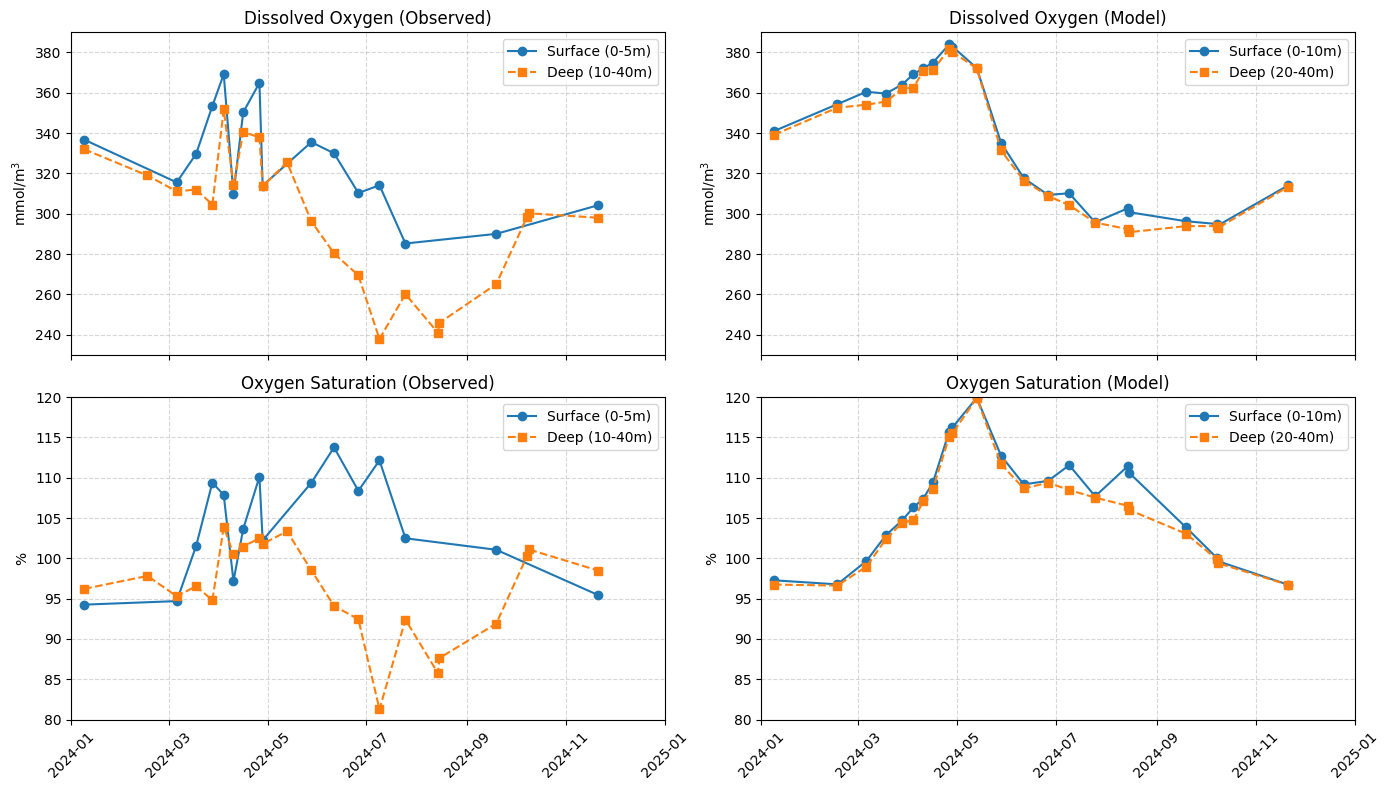

In [50]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# =========================
# Helper functions
# =========================
def extract_depth_avg_obs(ds, var_name, depth_range):
    flag_col = f"{var_name}_flag"
    data = ds[var_name]

    if flag_col in ds:
        data = data.where(ds[flag_col] == 2)

    data = data.where((data != -999) & (data >= 0))
    filtered_var = data.mean("HV", skipna=True)
    return filtered_var.sel(depth_bin=slice(*depth_range)).mean(
        dim="depth_bin", skipna=True
    )


def extract_depth_avg_da(da, depth_range):
    clean_da = da.where((da != -999) & (da >= 0) & (da <= 200))
    return (
        clean_da.mean("HV", skipna=True)
        .sel(depth_bin=slice(*depth_range))
        .mean(dim="depth_bin", skipna=True)
    )


def extract_depth_avg_model(var, depth_range):
    return (
        var.mean("location", skipna=True)
        .sel(depth=slice(*depth_range))
        .mean(dim="depth", skipna=True)
    )


# Function to calculate oxygen saturation percentage (%) via Garcia & Gordon (1992)
def calculate_o2_saturation(o2_conc, temp_c, salinity=34.0, is_ml_l=False):
    o2_clean = o2_conc.where(o2_conc != -999)

    if is_ml_l:
        o2_clean = o2_clean * 44.661

    tk = temp_c + 273.15
    ts = np.log((298.15 - temp_c) / tk)

    A0, A1, A2, A3, A4, A5 = (
        2.00907,
        3.22014,
        4.05010,
        4.94457,
        -0.256847,
        3.88767,
    )
    B0, B1, B2, B3 = -0.00624523, -0.00737614, -0.0103410, -0.00817083
    C0 = -0.000000488682

    ln_solubility = (
        A0
        + A1 * ts
        + A2 * ts**2
        + A3 * ts**3
        + A4 * ts**4
        + A5 * ts**5
        + salinity * (B0 + B1 * ts + B2 * ts**2 + B3 * ts**3)
        + C0 * salinity**2
    )

    o2_sol_ml_l = np.exp(ln_solubility)
    o2_sol_mmol_m3 = o2_sol_ml_l * 44.661

    sat_pct = (o2_clean / o2_sol_mmol_m3) * 100.0
    return sat_pct


# =========================
# Depth ranges
# =========================
upper_depth_range = (0, 5)
lower_depth_range = (10, 40)

upper_depth_range_m = (-0.5, -10)
lower_depth_range_m = (-20, -40)

# =========================
# Compute saturation
# =========================
obs_o2_sat = calculate_o2_saturation(
    obs["Oxygen"], obs["Temperature_CTD"], is_ml_l=True
)
model_o2_sat = calculate_o2_saturation(
    bgc_sub["O2"], phys_sub["temp"], is_ml_l=False
)


# =========================
# Figure Setup (2x2 Grid)
# =========================
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 8), sharex=True)

# -------------------------------------------------
# ROW 0: DISSOLVED OXYGEN
# -------------------------------------------------
# --- OBS (multiplied by 44.661) ---
ax_obs_0 = axes[0, 0]
obs_upper_o2 = extract_depth_avg_obs(obs, "Oxygen", upper_depth_range) * 44.661
obs_lower_o2 = extract_depth_avg_obs(obs, "Oxygen", lower_depth_range) * 44.661

mask_u = np.isfinite(obs_upper_o2)
mask_l = np.isfinite(obs_lower_o2)

ax_obs_0.plot(
    obs["time"][mask_u], obs_upper_o2[mask_u], label="Surface (0-5m)", marker="o"
)
ax_obs_0.plot(
    obs["time"][mask_l],
    obs_lower_o2[mask_l],
    label="Deep (10-40m)",
    linestyle="--",
    marker="s",
)
ax_obs_0.set_title("Dissolved Oxygen (Observed)")
ax_obs_0.set_ylabel("mmol/m$^3$")
ax_obs_0.legend()

# --- MODEL ---
ax_model_0 = axes[0, 1]
model_upper_o2 = extract_depth_avg_model(bgc_sub["O2"], upper_depth_range_m)
model_lower_o2 = extract_depth_avg_model(bgc_sub["O2"], lower_depth_range_m)

m_mask_u = np.isfinite(model_upper_o2)
m_mask_l = np.isfinite(model_lower_o2)

ax_model_0.plot(
    bgc_sub["time"][m_mask_u],
    model_upper_o2[m_mask_u],
    label="Surface (0-10m)",
    marker="o",
)
ax_model_0.plot(
    bgc_sub["time"][m_mask_l],
    model_lower_o2[m_mask_l],
    label="Deep (20-40m)",
    linestyle="--",
    marker="s",
)
ax_model_0.set_title("Dissolved Oxygen (Model)")
ax_model_0.set_ylabel("mmol/m$^3$")
ax_model_0.legend()


# -------------------------------------------------
# ROW 1: OXYGEN SATURATION (%)
# -------------------------------------------------
# --- OBS ---
ax_obs_1 = axes[1, 0]
obs_upper_sat = extract_depth_avg_da(obs_o2_sat, upper_depth_range)
obs_lower_sat = extract_depth_avg_da(obs_o2_sat, lower_depth_range)

mask_u_sat = np.isfinite(obs_upper_sat)
mask_l_sat = np.isfinite(obs_lower_sat)

ax_obs_1.plot(
    obs["time"][mask_u_sat],
    obs_upper_sat[mask_u_sat],
    label="Surface (0-5m)",
    marker="o",
)
ax_obs_1.plot(
    obs["time"][mask_l_sat],
    obs_lower_sat[mask_l_sat],
    label="Deep (10-40m)",
    linestyle="--",
    marker="s",
)
ax_obs_1.set_title("Oxygen Saturation (Observed)")
ax_obs_1.set_ylabel("%")
ax_obs_1.legend()

# --- MODEL ---
ax_model_1 = axes[1, 1]
model_upper_sat = extract_depth_avg_model(model_o2_sat, upper_depth_range_m)
model_lower_sat = extract_depth_avg_model(model_o2_sat, lower_depth_range_m)

m_mask_u_sat = np.isfinite(model_upper_sat)
m_mask_l_sat = np.isfinite(model_lower_sat)

ax_model_1.plot(
    bgc_sub["time"][m_mask_u_sat],
    model_upper_sat[m_mask_u_sat],
    label="Surface (0-10m)",
    marker="o",
)
ax_model_1.plot(
    bgc_sub["time"][m_mask_l_sat],
    model_lower_sat[m_mask_l_sat],
    label="Deep (20-40m)",
    linestyle="--",
    marker="s",
)
ax_model_1.set_title("Oxygen Saturation (Model)")
ax_model_1.set_ylabel("%")
ax_model_1.legend()


# =========================
# Shared Y-Limits & Formatting
# =========================
# Top row y-limits: 230 to 390 (Dissolved Oxygen)
ax_obs_0.set_ylim(230, 390)
ax_model_0.set_ylim(230, 390)

# Bottom row y-limits: 80 to 120 (Oxygen Saturation %)
ax_obs_1.set_ylim(80, 120)
ax_model_1.set_ylim(80, 120)

for ax in axes.flat:
    ax.tick_params(axis="x", rotation=45)
    ax.set_xlim([pd.Timestamp("2024-01-01"), pd.Timestamp("2025-01-01")])
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [41]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# =========================
# Helper functions
# =========================
def extract_depth_avg_obs(ds, var_name, depth_range):
    flag_col = f"{var_name}_flag"
    data = ds[var_name]
    
    if flag_col in ds:
        data = data.where(ds[flag_col] == 2)
        
    data = data.where((data != -999) & (data >= 0))
    filtered_var = data.mean('HV', skipna=True)
    return filtered_var.sel(depth_bin=slice(*depth_range)).mean(dim='depth_bin', skipna=True)

def extract_depth_avg_da(da, depth_range):
    clean_da = da.where((da != -999) & (da >= 0) & (da <= 200))
    return clean_da.mean('HV', skipna=True).sel(depth_bin=slice(*depth_range)).mean(dim='depth_bin', skipna=True)

def extract_depth_avg_model(var, depth_range):
    return var.mean('location', skipna=True).sel(depth=slice(*depth_range)).mean(dim='depth', skipna=True)

# Function to calculate oxygen saturation percentage (%) via Garcia & Gordon (1992)
def calculate_o2_saturation(o2_conc, temp_c, salinity=34.0, is_ml_l=False):
    o2_clean = o2_conc.where(o2_conc != -999)
    
    if is_ml_l:
        o2_clean = o2_clean * 44.661
    
    tk = temp_c + 273.15
    ts = np.log((298.15 - temp_c) / tk)
    
    A0, A1, A2, A3, A4, A5 = 2.00907, 3.22014, 4.05010, 4.94457, -0.256847, 3.88767
    B0, B1, B2, B3 = -0.00624523, -0.00737614, -0.0103410, -0.00817083
    C0 = -0.000000488682
    
    ln_solubility = (A0 + A1 * ts + A2 * ts**2 + A3 * ts**3 + A4 * ts**4 + A5 * ts**5 +
                     salinity * (B0 + B1 * ts + B2 * ts**2 + B3 * ts**3) + C0 * salinity**2)
    
    o2_sol_ml_l = np.exp(ln_solubility)
    o2_sol_mmol_m3 = o2_sol_ml_l * 44.661  
    
    sat_pct = (o2_clean / o2_sol_mmol_m3) * 100.0
    return sat_pct

# =========================
# Depth ranges
# =========================
upper_depth_range = (0, 5)    
lower_depth_range = (10, 40)  

upper_depth_range_m = (-0.5, -10)
lower_depth_range_m = (-20, -40)

# =========================
# Compute saturation using Oxygen_CTD
# =========================
obs_o2_sat = calculate_o2_saturation(obs['Oxygen_CTD'], obs['Temperature_CTD'], is_ml_l=True)
model_o2_sat = calculate_o2_saturation(bgc_sub['O2'], phys_sub['temp'], is_ml_l=False)


# =========================
# Figure Setup (2x2 Grid)
# =========================
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 8), sharex=True)

# -------------------------------------------------
# ROW 0: DISSOLVED OXYGEN
# -------------------------------------------------
# --- OBS (using Oxygen_CTD, multiplied by 44.661) ---
ax_obs_0 = axes[0, 0]
obs_upper_o2 = extract_depth_avg_obs(obs, 'Oxygen_CTD', upper_depth_range) * 44.661
obs_lower_o2 = extract_depth_avg_obs(obs, 'Oxygen_CTD', lower_depth_range) * 44.661

mask_u = np.isfinite(obs_upper_o2)
mask_l = np.isfinite(obs_lower_o2)

ax_obs_0.plot(obs['time'][mask_u], obs_upper_o2[mask_u], label='Surface (0-5m)', marker='o')
ax_obs_0.plot(obs['time'][mask_l], obs_lower_o2[mask_l], label='Deep (10-40m)', linestyle='--', marker='s')
ax_obs_0.set_title("Dissolved Oxygen - CTD (Observed)")
ax_obs_0.set_ylabel("mmol/m$^3$")
ax_obs_0.legend()

# --- MODEL ---
ax_model_0 = axes[0, 1]
model_upper_o2 = extract_depth_avg_model(bgc_sub['O2'], upper_depth_range_m)
model_lower_o2 = extract_depth_avg_model(bgc_sub['O2'], lower_depth_range_m)

m_mask_u = np.isfinite(model_upper_o2)
m_mask_l = np.isfinite(model_lower_o2)

ax_model_0.plot(bgc_sub['time'][m_mask_u], model_upper_o2[m_mask_u], label='Surface (0-10m)', marker='o')
ax_model_0.plot(bgc_sub['time'][m_mask_l], model_lower_o2[m_mask_l], label='Deep (20-40m)', linestyle='--', marker='s')
ax_model_0.set_title("Dissolved Oxygen (Model)")
ax_model_0.set_ylabel("mmol/m$^3$")
ax_model_0.legend()


# -------------------------------------------------
# ROW 1: OXYGEN SATURATION (%)
# -------------------------------------------------
# --- OBS ---
ax_obs_1 = axes[1, 0]
obs_upper_sat = extract_depth_avg_da(obs_o2_sat, upper_depth_range)
obs_lower_sat = extract_depth_avg_da(obs_o2_sat, lower_depth_range)

mask_u_sat = np.isfinite(obs_upper_sat)
mask_l_sat = np.isfinite(obs_lower_sat)

ax_obs_1.plot(obs['time'][mask_u_sat], obs_upper_sat[mask_u_sat], label='Surface (0-5m)', marker='o')
ax_obs_1.plot(obs['time'][mask_l_sat], obs_lower_sat[mask_l_sat], label='Deep (10-40m)', linestyle='--', marker='s')
ax_obs_1.set_title("Oxygen Saturation - CTD (Observed)")
ax_obs_1.set_ylabel("%")
ax_obs_1.legend()

# --- MODEL ---
ax_model_1 = axes[1, 1]
model_upper_sat = extract_depth_avg_model(model_o2_sat, upper_depth_range_m)
model_lower_sat = extract_depth_avg_model(model_o2_sat, lower_depth_range_m)

m_mask_u_sat = np.isfinite(model_upper_sat)
m_mask_l_sat = np.isfinite(model_lower_sat)

ax_model_1.plot(bgc_sub['time'][m_mask_u_sat], model_upper_sat[m_mask_u_sat], label='Surface (0-10m)', marker='o')
ax_model_1.plot(bgc_sub['time'][m_mask_l_sat], model_lower_sat[m_mask_l_sat], label='Deep (20-40m)', linestyle='--', marker='s')
ax_model_1.set_title("Oxygen Saturation (Model)")
ax_model_1.set_ylabel("%")
ax_model_1.legend()


# =========================
# Formatting
# =========================
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)
    ax.set_xlim([pd.Timestamp('2024-01-01'),
                 pd.Timestamp('2025-01-01')])

plt.tight_layout()
plt.show()

NameError: name 'phys_sub' is not defined

## Chlorophyll and iron per cruise, all depths

Mean ± one standard deviation over all stations and depths for each of the first 22 observation dates: observed chlorophyll-a (left), and modeled chlorophyll (`spChl` + `diatChl`) with modeled iron (`Fe`) on a secondary axis (right).

NameError: name 'ax_bat' is not defined

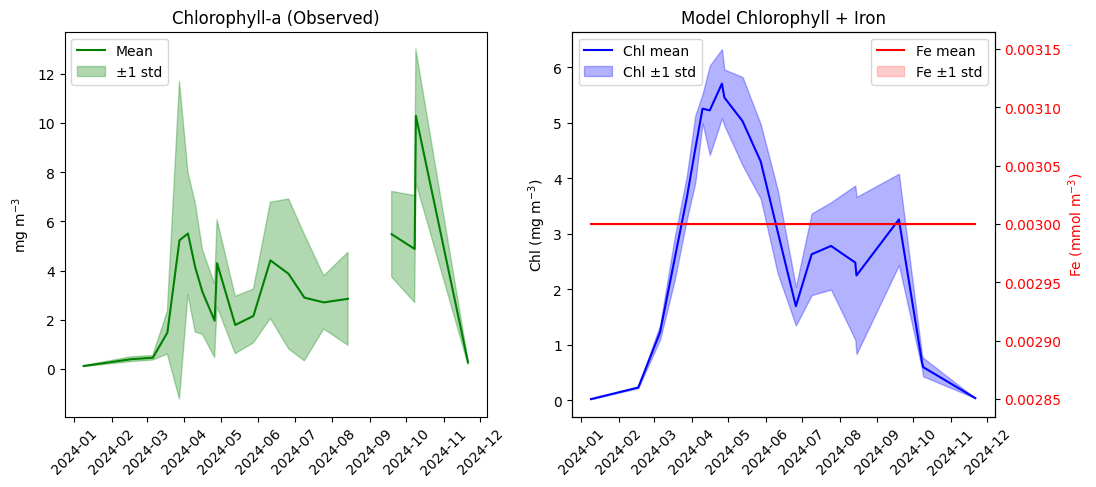

In [42]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# =========================
# Figure setup
# =========================
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

# =========================
# Helper functions
# =========================
def extract_cruise_stats(data_list):
    """Convert list of arrays into mean and std arrays."""
    means = np.array([np.nanmean(d) if len(d) > 0 else np.nan for d in data_list])
    stds  = np.array([np.nanstd(d)  if len(d) > 0 else np.nan for d in data_list])
    return means, stds


def extract_cruise_data_all_depths(ds, var_name, num_cruises=22):
    var = ds[var_name]
    cruises = []
    for i in range(num_cruises):
        data = np.hstack(var.isel(time=i))
        cruises.append(data[~np.isnan(data)])
    return cruises


def extract_model_data_all_depths(var, num_cruises=22):
    cruises = []
    for i in range(num_cruises):
        data = np.hstack(var.isel(time=i))
        cruises.append(data[~np.isnan(data)])
    return cruises

# =========================
# Time axis
# =========================
time = pd.to_datetime(obs['time'].isel(time=slice(0, 22)))

# =========================
# --- OBSERVED (chl_a) ---
# =========================
ax_obs = axes[0]

chl_obs = extract_cruise_data_all_depths(obs, 'chl_a')
mean_obs, std_obs = extract_cruise_stats(chl_obs)

ax_obs.plot(time, mean_obs, color='green', label='Mean')
ax_obs.fill_between(
    time,
    mean_obs - std_obs,
    mean_obs + std_obs,
    color='green',
    alpha=0.3,
    label='±1 std'
)

ax_obs.set_title("Chlorophyll-a (Observed)")
ax_obs.set_ylabel("mg m$^{-3}$")
ax_obs.legend()
ax_obs.tick_params(axis='x', rotation=45)

# =========================
# --- MODEL (chl + Fe) ---
# =========================
ax_model = axes[1]

# --- Chlorophyll ---
chl_model = extract_model_data_all_depths(
    bgc_sub['spChl'] + bgc_sub['diatChl']
)

mean_chl, std_chl = extract_cruise_stats(chl_model)

ax_model.plot(time, mean_chl, color='blue', label='Chl mean')
ax_model.fill_between(
    time,
    mean_chl - std_chl,
    mean_chl + std_chl,
    color='blue',
    alpha=0.3,
    label='Chl ±1 std'
)

ax_model.set_title("Model Chlorophyll + Iron")
ax_model.set_ylabel("Chl (mg m$^{-3}$)")
ax_model.tick_params(axis='x', rotation=45)

# =========================
# --- SECONDARY AXIS (Fe) ---
# =========================
ax_fe = ax_model.twinx()

fe_model = extract_model_data_all_depths(bgc_sub['Fe'])
mean_fe, std_fe = extract_cruise_stats(fe_model)

ax_fe.plot(time, mean_fe, color='red', label='Fe mean')
ax_fe.fill_between(
    time,
    mean_fe - std_fe,
    mean_fe + std_fe,
    color='red',
    alpha=0.2,
    label='Fe ±1 std'
)

ax_fe.set_ylabel("Fe (mmol m$^{-3}$)", color='red')
ax_fe.tick_params(axis='y', labelcolor='red')

# =========================
# Legends (separate axes)
# =========================
ax_model.legend(loc='upper left')
ax_fe.legend(loc='upper right')

import datetime as dt

# ... (Keep all your previous map setup and plotting code the same) ...

# =================================================================
# Update Axis Limits and Ticks to restrict to 2024
# =================================================================

# Define your 2024 calendar boundaries
xlim_2024 = [dt.date(2024, 1, 1), dt.date(2024, 12, 31)]

# Apply to Panel (a) — Observed Chlorophyll
ax_map.set_xlim(xlim_2024)
# Clean up any leftover out-of-bounds tick labels
ax_map.set_xticks([dt.date(2024, 3, 1), dt.date(2024, 6, 1), 
                   dt.date(2024, 9, 1), dt.date(2024, 12, 1)])

# Apply to Panel (b) — Model Chlorophyll + Iron
ax_bat.set_xlim(xlim_2024)
ax_bat.set_xticks([dt.date(2024, 3, 1), dt.date(2024, 6, 1), 
                   dt.date(2024, 9, 1), dt.date(2024, 12, 1)])

# Adjust rotation for readability if the dates crowd the axis
fig.autofmt_xdate(rotation=45)

plt.show()

# =========================
# Layout
# =========================
plt.tight_layout()
plt.show()

## Repeated extraction of physical model fields

This cell repeats the extraction of `phys_sub` (physical model fields at the station positions and observation dates) that is already done in the data processing section.

In [43]:
import xarray as xr
import numpy as np

# 1. Extract temperature values across the selected locations
phys_values = []

for i in range(7):
    lat, lon = locations[i]
    # Select the 'temp' values at the nearest lat/lon from the physical dataset `phys`
    phys_selected = phys.sel(lat=lat, method='nearest').sel(lon=lon, method='nearest')
    phys_values.append(phys_selected)

# 2. Combine selections into an xarray Dataset and align coordinates
phys_values_combined = xr.concat(phys_values, dim='location')
phys_values_combined = phys_values_combined.assign_coords(location=('location', [1, 3, 5, 7, 9, 10, 12]))

if 'depth' in phys_values_combined.coords:
    phys_values_combined['depth'] = phys_values_combined.depth * (-1)

# 3. Select nearest model output using the unique cruise observation dates
time_list = np.unique(obs['time'].values)
phys_sub = phys_values_combined.sel(
    time=time_list,
    method='nearest'
)

# 4. Overwrite coordinate labels to perfectly mirror the precise 'obs' timeline
phys_sub = phys_sub.assign_coords(time=time_list).load()

## Data availability of observed oxygen

Counts the missing values in the observed `Oxygen` variable and the number of non-missing values per depth bin.

In [44]:
# Check total values vs NaN count in the raw observation variable
total_vals = obs['Oxygen'].size
nan_vals = obs['Oxygen'].isnull().sum().item()
print(f"Total entries in obs['Oxygen']: {total_vals}")
print(f"NaN entries: {nan_vals} ({nan_vals / total_vals * 100:.1f}%)")

# Check if a specific depth range or time slice is entirely NaN
print("\nNon-null count per depth bin:")
print(obs['Oxygen'].notnull().sum(dim=['HV', 'time']))

Total entries in obs['Oxygen']: 2376
NaN entries: 1943 (81.8%)

Non-null count per depth bin:
<xarray.DataArray 'Oxygen' (depth_bin: 9)> Size: 72B
array([108,  88, 111,  65,   6,  27,   9,  14,   5])
Coordinates:
  * depth_bin  (depth_bin) int64 72B 0 10 20 30 40 50 60 70 80


## Moored pCO$_2$ sensor and model surface pCO$_2$, November 2024

Daily mean ± standard deviation of the moored pCO$_2$ sensor record (`2024-11-05_2024-12-10+pCO2_moored.txt`) for November 2024, next to model surface pCO$_2$ (`pCO2SURF`) at grid point eta_rho = 248, xi_rho = 456. The model values come from the `bgc_dia` output of the run `Iceland2_MARBL_2024_60m`, not from the `iceland2_customriver` run used above. The figure is saved as `pCO2_sensor_vs_model_daily_November_2024.jpeg` in `PROJECT_ROOT`.

Found 4 model files for November 2024.


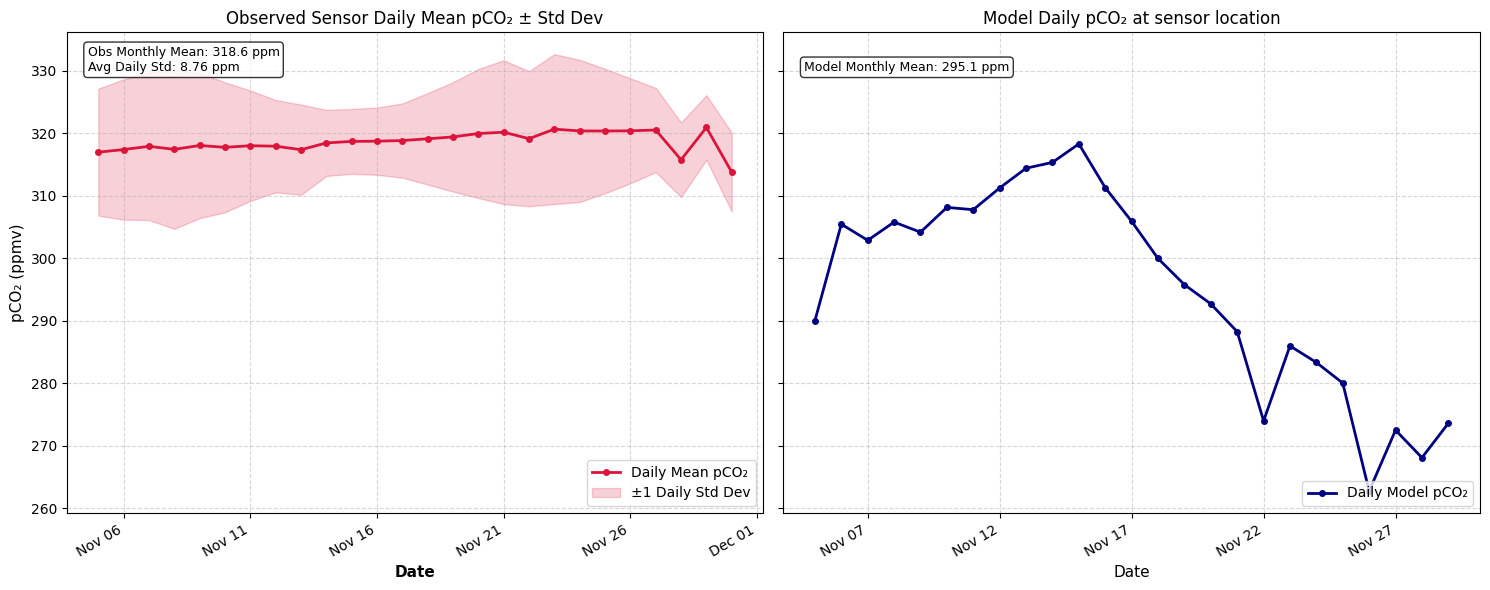

In [45]:
import glob
import os
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

# ====================================================
# Paths & Configuration
# ====================================================
PROJECT_ROOT = "/anvil/projects/x-ees250129/x-uheede/C-Star-in-Hvalfjordur"
sensor_file_path = f"{PROJECT_ROOT}/data/2024-11-05_2024-12-10+pCO2_moored.txt"

model_dir = "/anvil/scratch/x-uheede/Iceland2_MARBL_2024_60m/"
model_files_pattern = os.path.join(
    model_dir, "Iceland2_MARBL_2024_bgc_dia.202411*.nc"
)

# Target model grid cell coordinates
i_target = 456  # xi_rho
j_target = 248  # eta_rho

# ====================================================
# 1. Load & Resample Moored pCO2 Sensor Data
# ====================================================
cols = [
    "Mode",
    "Year",
    "Month",
    "Day",
    "Hour",
    "Minute",
    "Second",
    "SampleNum",
    "RecordNum",
    "CO2_ppm",
    "TempWater_C",
    "DetV_V",
    "LampV_V",
    "Status",
    "TempInternal_C",
    "TempBench_C",
    "SupplyV_V",
]

df_sensor = pd.read_csv(sensor_file_path, sep=",", names=cols)
df_sensor["time"] = pd.to_datetime(
    df_sensor[["Year", "Month", "Day", "Hour", "Minute", "Second"]]
)
df_sensor = df_sensor.set_index("time")

# Filter for November 2024 only
df_sensor_nov = df_sensor[
    (df_sensor.index.year == 2024) & (df_sensor.index.month == 11)
]

# Resample Sensor Data to Daily Means and Daily Std Dev
df_sensor_daily = df_sensor_nov["CO2_ppm"].resample("D").agg(["mean", "std"])

# ====================================================
# 2. Load Model Surface pCO2 Data
# ====================================================
model_files = sorted(glob.glob(model_files_pattern))

if not model_files:
    # Fallback search path if files reside in project scratch root
    model_files = sorted(
        glob.glob(
            "/anvil/projects/x-ees250129/x-uheede/Iceland_experiments/Iceland2_MARBL_2024_60m/Iceland2_MARBL_2024_bgc_dia.202411*.nc"
        )
    )

print(f"Found {len(model_files)} model files for November 2024.")

ds_model = xr.open_mfdataset(model_files, combine="nested", concat_dim="time")

# Convert ROMS ocean_time ("seconds since 2000-01-01") to pandas datetime
raw_time = ds_model["ocean_time"].values
if np.issubdtype(raw_time.dtype, np.datetime64):
    model_time = pd.to_datetime(raw_time)
else:
    model_time = pd.to_datetime("2000-01-01") + pd.to_timedelta(
        raw_time, unit="s"
    )

# Extract pCO2SURF at grid point (eta_rho=248, xi_rho=456)
pco2_model = ds_model["pCO2SURF"].isel(eta_rho=j_target, xi_rho=i_target).values

df_model_raw = pd.DataFrame(
    {"time": model_time, "pCO2_ppm": pco2_model}
).set_index("time")

# Filter strictly for November 2024
df_model_nov = df_model_raw[
    (df_model_raw.index.year == 2024) & (df_model_raw.index.month == 11)
]

ds_model.close()

# ====================================================
# 3. Side-by-Side Plot Generation
# ====================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# --- Left Panel: Observed Sensor Daily Means + Std Dev ---
ax1.plot(
    df_sensor_daily.index,
    df_sensor_daily["mean"],
    color="crimson",
    marker="o",
    markersize=4,
    linewidth=2.0,
    label="Daily Mean pCO₂",
)
ax1.fill_between(
    df_sensor_daily.index,
    df_sensor_daily["mean"] - df_sensor_daily["std"],
    df_sensor_daily["mean"] + df_sensor_daily["std"],
    color="crimson",
    alpha=0.2,
    label="±1 Daily Std Dev",
)
ax1.set_title(
    "Observed Sensor Daily Mean pCO₂ ± Std Dev",
    fontsize=12
)
ax1.set_ylabel("pCO₂ (ppmv)", fontsize=11)
ax1.set_xlabel("Date", fontsize=11, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="lower right", frameon=True)

# Annotate Observed Stats
sensor_mean = df_sensor_daily["mean"].mean()
sensor_avg_std = df_sensor_daily["std"].mean()
ax1.text(
    0.03,
    0.92,
    f"Obs Monthly Mean: {sensor_mean:.1f} ppm\nAvg Daily Std: {sensor_avg_std:.2f} ppm",
    transform=ax1.transAxes,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8),
    fontsize=9,
)

# --- Right Panel: Model Daily Surface pCO2 (No Std Dev) ---
ax2.plot(
    df_model_nov.index,
    df_model_nov["pCO2_ppm"],
    color="navy",
    marker="o",
    markersize=4,
    linewidth=2.0,
    label="Daily Model pCO₂",
)
ax2.set_title(
    f"Model Daily pCO₂ at sensor location",
    fontsize=12
)
ax2.set_xlabel("Date", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="lower right", frameon=True)

# Annotate Model Stats
model_mean = df_model_nov["pCO2_ppm"].mean()
ax2.text(
    0.03,
    0.92,
    f"Model Monthly Mean: {model_mean:.1f} ppm",
    transform=ax2.transAxes,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8),
    fontsize=9,
)

# Format X-axis date ticks for both subplots
for ax in [ax1, ax2]:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

plt.tight_layout()
out_fig_path = os.path.join(
    PROJECT_ROOT, "pCO2_sensor_vs_model_daily_November_2024.jpeg"
)
plt.savefig(out_fig_path, format="jpeg", dpi=300)
plt.show()

#print(f"Plot saved to: {out_fig_path}")